# E100 · Chasing the hotspot: an adaptive radiation survey replayed on real Safecast readings

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: **301,693 readings** from Safecast's volunteer **bGeigie** radiation loggers (CC0), taken from the public API: every reading within 12 km of **Iitate village, Fukushima**, from September 2011 to June 2013, and within 6 km of the western edge of **Minamisoma** in 2012. A reading is a one-minute gamma count (cpm) with a time, a GPS position and the log (one device on one trip) it came from |
| **You will learn** | What a citizen-science radiation reading is, and the traps in it: **logs uploaded twice**, **two devices in one car**, trip-to-trip offsets, heavy tails · why a radiation field **does not stand still** (Cs-134/137 decay, weathering, **snow**) and how to choose a survey season · a **2-D HSGP field with trip effects and a Student-t likelihood** in PyMC, fitted next door; a prior predictive check; a **failure** (no trip effects) caught by a **posterior predictive check**; the **lengthscale-amplitude ridge** and the quantity the data do identify · a **counterfactual replay**: each stop reveals one real logged reading, without replacement, scored against a truth the survey never sees · an **online GP belief** with Student-t readings (EM reweighting), a learned amplitude and **Matheron** draws · acquisition with a **travel budget**: a fixed grid, random stops, **UCB** (near and far), **Thompson sampling**, a **one-step lookahead** on the closure decision, and hybrids that split the day · scoring **finding** a hotspot and **bounding** a hazard separately, and turning the belief into a road-closure decision |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # single-threaded linear algebra: the same seed gives the same fit on every run

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import xarray as xr
from scipy import stats
from scipy.cluster.vq import kmeans2
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from scipy.special import ndtr

from pymc_challenges import data

RANDOM_SEED = 100
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()

BLUE, ORANGE, AQUA, PURPLE, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8c5ac8", "#c8384e"
INK, MUTED, LIGHT = "#222222", "#8a8984", "#d9d8d3"
CPM_PER_USVH = 334.0  # Safecast's conversion for the LND 7317 tube (Cs-137 calibration)
THR_USVH = 3.8  # the 20 mSv/year line used for evacuation orders
THR = np.log(THR_USVH * CPM_PER_USVH)  # in log cpm
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}; threshold {THR_USVH} uSv/h = {np.exp(THR):.0f} cpm")

PyMC 6.3.2, ArviZ 1.3.0; threshold 3.8 uSv/h = 1269 cpm


## The setting

On 15 March 2011, four days after the earthquake and tsunami, the wind carried the plume from the Fukushima
Daiichi nuclear power plant north-west, and rain brought caesium down over the hills 30-45 km away.
**Iitate**, a farming village of about 6,000 people, had not been in the 20-km evacuation zone; it was
ordered to evacuate in late April, about six weeks later, and its southern district, Nagadoro, stayed closed
for years after the rest reopened. In the first year nobody had a fine-grained map of what was on the
ground. Official airborne surveys gave kilometre-scale pictures; what people needed to know was which
stretch of *which road* was hot.

**Safecast**, a volunteer group formed in the days after the accident, answered with a device: the bGeigie,
a Geiger counter with a GPS in a box that is mounted on a car window and logs a reading every five seconds
(Brown et al. 2016). Volunteers drove it over Fukushima for years and published every log. Car-borne surveys
like this one, and the government's own (Andoh et al. 2015), became the main way to map air dose rate along
roads.

This notebook takes the point of view of one field team with one car and a day's budget: **40 stops**, and
at most **4 km of road** between consecutive stops. The team has two jobs. The first is to **find the
hotspot**, the hottest stretch of road in the district, where the decontamination crew should start. The
second is to **bound the hazard**: to say which road cells are above 3.8 uSv/h, the dose rate that the
government's formula turns into 20 mSv a year and that set the evacuation line, so that those cells can be
signed and closed. Both are questions about where to stop next, given everything measured so far.

That is adaptive sampling. The statistical ideas are old: Thompson (1933) sampling from the posterior,
upper confidence bounds for Gaussian processes (GP-UCB; Srinivas et al. 2010), straddle and level-set rules
for mapping where a function crosses a threshold (Bryan et al. 2006; Gotovos et al. 2013), and informative
path planning, where a sensor that moves pays for distance as well as for measurements (Singh et al. 2009).
E82 used acquisition functions to choose experiments from a table; there the next experiment could be
anything. Here the observer **moves**, every reading is **noisy** in ways a table of yields is not, and the
two jobs pull in different directions.

The test is done on real data without a simulator. Safecast drove Iitate's roads many times, so most road
cells have dozens of real readings from different days and devices. A survey in this notebook chooses a
cell, and the cell **reveals one of its real logged readings**, drawn without replacement. The noise is the
real noise: counting statistics, a car door shielding the tube, a five-second reading that averaged a minute
of driving, a different device on a different day. The truth used for scoring is a robust summary of *all*
the readings in the cell, which the survey never sees. The replay lets us run the same day from 40 different
starting points with every policy, and count.

| part | question | tool |
|---|---|---|
| A | What is a reading? | Safecast logs, duplicate uploads, two devices in one car, 250 m cells, heavy tails |
| B | Does the field stand still? | decay of Cs-134 and Cs-137, repeat cells, snow, a survey season |
| C | What does the field look like next door? | an HSGP field with trip effects and Student-t noise in PyMC; prior predictive; a failure and its fix; a mixed predictive check; the lengthscale ridge |
| D | What will the survey face? | Iitate's road cells, a hidden truth, the replay |
| E | What does the team believe after each stop? | an online GP update with Student-t readings and a learned amplitude; one survey, three closure maps |
| F | Where should the next stop be? | grid, random, UCB near and far, Thompson, a one-step lookahead, hybrids; three ways to declare a hotspot; 40 replays |
| G | How does the answer grow with the readings? | curves against the number of stops |
| H | What does the team decide? | the borrowed vs learned amplitude, choosing the day, the declared hotspot, a bound on the maximum, the closure list |

## A · What is a reading?

In [2]:
data.describe("safecast_iitate")
raw = data.load("safecast_iitate")
raw["t"] = pd.to_datetime(raw["captured_at"])
dup = raw.duplicated(["captured_at", "latitude", "longitude", "cpm"])
print(f"\n{len(raw):,} readings in {raw.import_id.nunique()} uploaded logs, "
      f"{raw.t.min():%Y-%m-%d} to {raw.t.max():%Y-%m-%d}")
print(f"exact copies (same time, place and count, another log id): {dup.sum():,} rows "
      f"in {raw[dup].import_id.nunique()} logs")
df = raw[~dup].copy()

# two devices in the same car: logs 11421 and 11169 on 19 May 2012
a = df[df.import_id == 11421].set_index("captured_at")
b = df[df.import_id == 11169].set_index("captured_at")
j = a.join(b, lsuffix="_a", rsuffix="_b", how="inner")
gap_m = np.hypot(j.latitude_a - j.latitude_b, (j.longitude_a - j.longitude_b) * np.cos(np.radians(37.66))) * 111_000
print(f"logs 11421 and 11169: {len(j)} shared timestamps, positions {np.median(gap_m):.0f} m apart (median), "
      f"cpm ratio {np.median(j.cpm_a / j.cpm_b):.2f}, correlation of log cpm "
      f"{np.corrcoef(np.log(j.cpm_a), np.log(j.cpm_b))[0, 1]:.2f}")
# every such pair: the same second, within 100 m, another log. Keep the lower log id's reading.
df = df.reset_index(drop=True)
df["row"] = np.arange(len(df))
cols_ = ["row", "captured_at", "latitude", "longitude", "import_id"]
same_t = df[df.duplicated("captured_at", keep=False)][cols_]
pairs = same_t.merge(same_t, on="captured_at")
pairs = pairs[pairs.import_id_x < pairs.import_id_y]
near = np.hypot(pairs.latitude_x - pairs.latitude_y,
                (pairs.longitude_x - pairs.longitude_y) * np.cos(np.radians(37.66))) * 111_000 < 100
pairs = pairs[near]
print(f"same second, within 100 m, two logs: {pairs.groupby(['import_id_x', 'import_id_y']).ngroups} pairs of "
      f"logs; dropping {pairs.row_y.nunique():,} readings from the second device")
df = df[~df.row.isin(pairs.row_y)].drop(columns="row")

safecast_iitate: One row per reading: id (Safecast measurement id), captured_at (UTC), latitude, longitude, cpm (counts per minute of the LND 7317 tube, a rolling one-minute count reported every 5 s; Safecast converts 334 cpm = 1 uSv/h for Cs-137), import_id (the uploaded log file: one device on one trip), user_id (uploader).
  source: Safecast (https://safecast.org) volunteer bGeigie mobile radiation logs, CC0 1.0 (public domain dedication). Snapshot of the public API on 2026-11-04: every reading within 12 km of Iitate village (37.66 N, 140.72 E) captured 2011-09-01 to 2013-06-30, and within 6 km of western Minamisoma (37.633 N, 140.913 E) captured in 2012, kept inside the box 37.54-37.78 N, 140.58-141.00 E. Values unchanged; rows not deduplicated (logs uploaded twice appear twice). DERIVED by tools/build_e100_data.py - keep the cached file (the API is slow and live).
  url:    https://api.safecast.org/en-US/measurements.json



301,693 readings in 160 uploaded logs, 2011-09-01 to 2013-06-30
exact copies (same time, place and count, another log id): 31,761 rows in 32 logs
logs 11421 and 11169: 555 shared timestamps, positions 10 m apart (median), cpm ratio 1.08, correlation of log cpm 0.99
same second, within 100 m, two logs: 45 pairs of logs; dropping 10,568 readings from the second device


The file is a straight snapshot of the API, and its first lesson is that a public archive of citizen data
needs cleaning before it can be counted. **31,761 rows are exact copies** - same second, same position, same
count - filed under another log id, because the same log was uploaded twice. We drop them. A subtler case
is not a duplicate at all: logs 11421 and 11169 were recorded on the same day at the same timestamps, 10 m
apart, with log counts correlated at 0.99 and one device reading 8% higher than the other. That is **two
bGeigies in one car**. Their readings are not independent evidence about the road, and their 8% calibration
difference is a first sign of what will matter most below: readings depend on the trip and device as well
as on the place.

This pair is not alone. Searching for readings from two logs in the same second and within 100 m of each
other finds **45 pairs of logs**, some of them three or four devices travelling together. Two such readings
tell us about one stretch of road at one moment, and counting them twice would make the archive look more
certain than it is. We keep the reading from the lower log id and drop the other, **10,568 readings** in
all.

We put the readings on a local grid in kilometres and cut it into **250 m cells**, the unit a survey can
stop at and a road sign can close. Two districts are used. **Iitate** (109,000 readings) is the district the
team will survey. The western edge of **Minamisoma** (148,000 readings in 2012), across the hills to the
east, is the neighbour whose data teach us what such a field looks like before the survey starts. A few
readings fall in the gap between them and are not used.

            readings  logs       first        last
district                                          
Iitate        109149   106  2011-09-01  2013-06-30
Minamisoma    148091    73  2012-01-07  2012-12-31
between         2124    62  2011-09-10  2013-06-30
beyond +-0.5 (a factor 1.65): 3.9% of readings; a normal with the same core spread predicts 0.04%


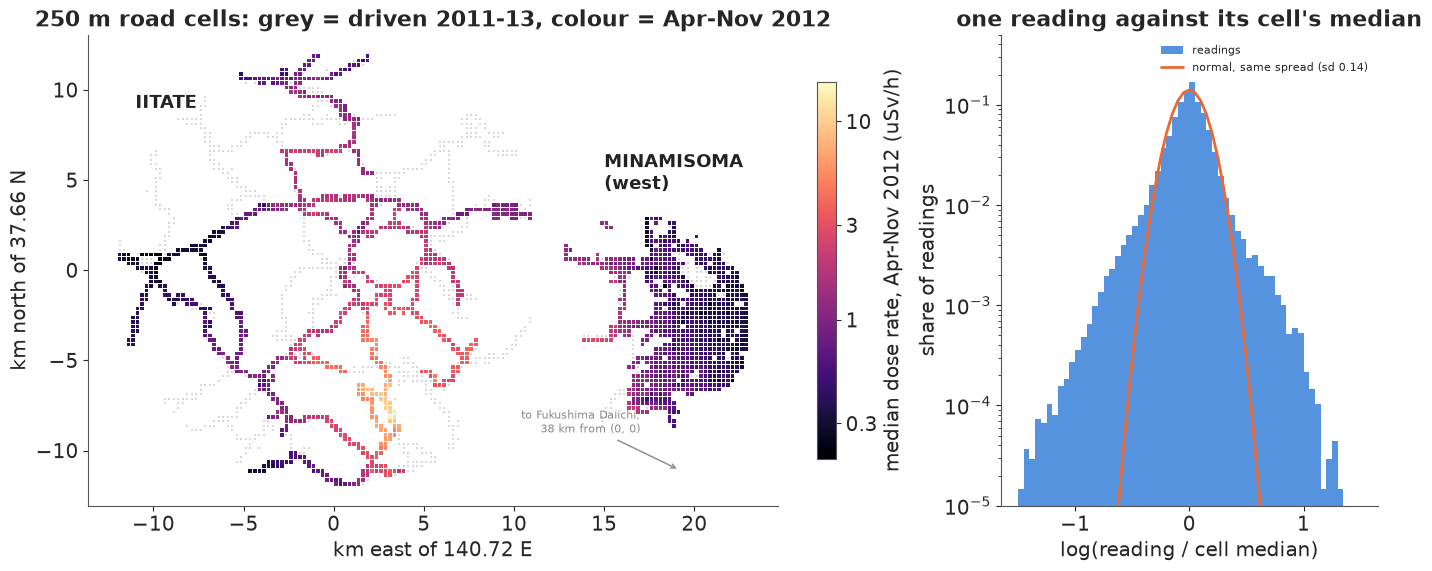

In [3]:
LAT0, LON0, CELL = 37.66, 140.72, 0.25  # origin of the local grid; 250 m cells
df["x"] = (df.longitude - LON0) * 111.32 * np.cos(np.radians(LAT0))  # km east
df["y"] = (df.latitude - LAT0) * 110.57  # km north
df["ix"] = np.floor(df.x / CELL).astype(int)
df["iy"] = np.floor(df.y / CELL).astype(int)
df["day"] = df.t.dt.strftime("%Y-%m-%d")
df["district"] = np.where(df.x < 11, "Iitate", np.where(df.x > 12, "Minamisoma", "between"))
print(df.groupby("district").agg(readings=("cpm", "size"), logs=("import_id", "nunique"),
                                 first=("day", "min"), last=("day", "max")))

WIN = ("2012-04-01", "2012-12-01")  # the survey season (section B)
win = df[(df.t >= WIN[0]) & (df.t < WIN[1]) & (df.district != "between")]
cellmed = (win.groupby(["district", "ix", "iy"])
           .agg(n=("cpm", "size"), days=("day", "nunique"), cpm=("cpm", "median")).reset_index())
resid = np.log(win.cpm) - np.log(win.groupby(["district", "ix", "iy"]).cpm.transform("median"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [2.1, 1]})
ax = axes[0]
road = df[df.district != "between"].groupby(["ix", "iy"]).size().reset_index()
ax.scatter((road.ix + 0.5) * CELL, (road.iy + 0.5) * CELL, s=3, color=LIGHT, marker="s", lw=0)
sc = ax.scatter((cellmed.ix + 0.5) * CELL, (cellmed.iy + 0.5) * CELL, c=np.log10(cellmed.cpm / CPM_PER_USVH),
                s=7, marker="s", cmap="magma", vmin=-0.7, vmax=1.2, lw=0)
cb = fig.colorbar(sc, ax=ax, shrink=0.8)
cb.set_ticks(np.log10([0.3, 1, 3, 10]), labels=["0.3", "1", "3", "10"])
cb.set_label("median dose rate, Apr-Nov 2012 (uSv/h)")
ax.text(-11, 9, "IITATE", fontsize=13, color=INK, weight="bold")
ax.text(15, 4.5, "MINAMISOMA\n(west)", fontsize=13, color=INK, weight="bold")
daiichi = np.array([(141.0325 - LON0) * 111.32 * np.cos(np.radians(LAT0)), (37.4214 - LAT0) * 110.57])
u = daiichi / np.hypot(*daiichi)
ax.annotate(f"to Fukushima Daiichi,\n{np.hypot(*daiichi):.0f} km from (0, 0)", xy=(17 + 3 * u[0], -9 + 3 * u[1]),
            xytext=(17, -9), fontsize=8, color=MUTED, ha="right", arrowprops=dict(arrowstyle="->", color=MUTED))
ax.set(xlabel="km east of 140.72 E", ylabel="km north of 37.66 N", aspect=1,
       title="250 m road cells: grey = driven 2011-13, colour = Apr-Nov 2012")
ax = axes[1]
bins = np.linspace(-1.5, 1.5, 61)
ax.hist(resid, bins=bins, color=BLUE, alpha=0.8, weights=np.full(len(resid), 1 / len(resid)), label="readings")
s_rob = 1.4826 * np.median(np.abs(resid))
ax.plot(bins, stats.norm.pdf(bins, 0, s_rob) * (bins[1] - bins[0]), color=ORANGE, lw=2,
        label=f"normal, same spread (sd {s_rob:.2f})")
ax.set(yscale="log", ylim=(1e-5, 0.5), xlabel="log(reading / cell median)", ylabel="share of readings",
       title="one reading against its cell's median")
ax.legend(fontsize=8);

print(f"beyond +-0.5 (a factor 1.65): {np.mean(np.abs(resid) > 0.5):.1%} of readings; "
      f"a normal with the same core spread predicts {2 * stats.norm.sf(0.5 / s_rob):.2%}")

The left map shows the road network the volunteers drove (grey) and the median dose rate of each cell in the
2012 survey season. Iitate's roads run from about 0.3 uSv/h in the west to more than 10 uSv/h in the south,
toward Nagadoro. Minamisoma's grid of streets is much lower, mostly under 1 uSv/h:
it lies further from the axis of the plume.

The right panel compares single readings with the median of their cell. The core is narrow: a normal curve
with sd 0.14 on the log scale fits the middle. The tails are not normal at all: 3.9% of readings are more
than a factor 1.65 (0.5 on the log scale) from their cell's median, where a normal with the same core would
put 0.04%. Some of that is genuine small-scale structure (a gutter, a drain, a patch of moss), some is a
reading that averaged a minute of driving through a hotter or cooler stretch, some is the device and trip.
Whatever the cause, a model that treats readings as normal will treat one stray reading as strong evidence.

## B · Does the field stand still?

A survey takes time and its readings come from different days, so we need to know how fast the field
changes. The physics is known. The fallout had roughly equal activities of **Cs-134** (half-life 2.07 years)
and **Cs-137** (30.2 years); Cs-134 emits more gamma energy per decay and gave about three quarters of the
dose rate at the start. The dose rate from decay alone is therefore

$$\frac{D(t)}{D(0)} = 0.73\, e^{-t \ln 2 / 2.065} + 0.27\, e^{-t \ln 2 / 30.17},$$

which falls by about 20% a year in 2012. Rain, soil migration and clean-up add to that, and snow on the
ground shields the gamma rays while it lies there. We measure all of it on Iitate's **repeat cells**: for
every month, the median log change of the cells that were also measured in May 2012.

  month  cells  change  physics
2011-09    407    0.28     0.16
2011-10    226    0.18     0.14
2011-11    263    0.10     0.12
2011-12     60    0.06     0.10
2012-01    138    0.04     0.08
2012-02    286   -0.15     0.06
2012-03    185   -0.16     0.04
2012-04    116    0.17     0.02
2012-05    430    0.00     0.00
2012-06     39   -0.50    -0.02
2012-09    240   -0.12    -0.08
2012-10    136   -0.18    -0.09
2012-11    231   -0.35    -0.11
2012-12    142   -0.89    -0.13
2013-01    135   -0.72    -0.15
2013-03    135   -0.55    -0.18
2013-04    373   -0.39    -0.20
2013-05    241   -0.38    -0.22
2013-06    164   -0.38    -0.23


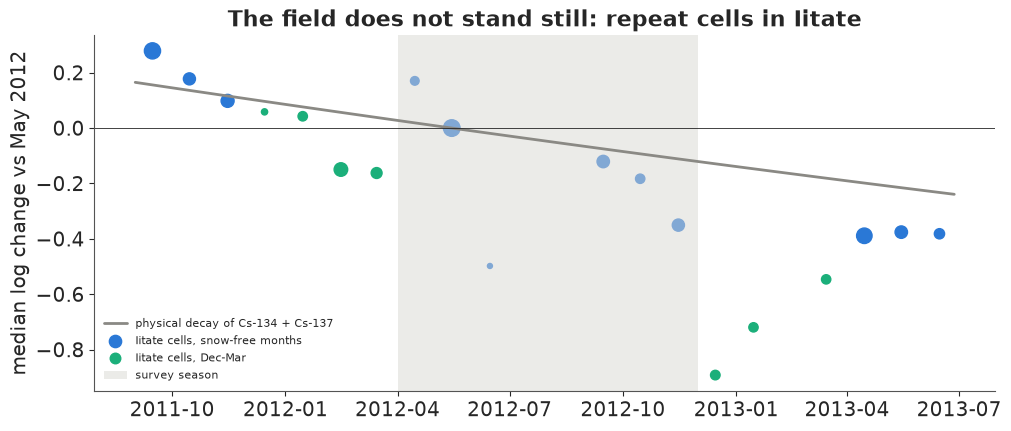

In [4]:
ACCIDENT = pd.Timestamp("2011-03-15", tz="UTC")
T_REF = pd.Timestamp("2012-08-01", tz="UTC")


def log_decay(t):
    """log of the physical dose-rate factor at t (years after 15 March 2011): Cs-134 and Cs-137 released
    in equal activity, Cs-134 giving ~73% of the dose rate at the start (half-lives 2.065 and 30.17 years)."""
    return np.log(0.73 * np.exp(-np.log(2) * t / 2.065) + 0.27 * np.exp(-np.log(2) * t / 30.17))


def years(ts):
    return (ts - ACCIDENT).dt.days.to_numpy() / 365.25 if hasattr(ts, "dt") else (ts - ACCIDENT).days / 365.25


ii = df[df.district == "Iitate"].copy()
ii["month"] = ii.t.dt.strftime("%Y-%m")
piv = ii.groupby(["ix", "iy", "month"]).cpm.median().apply(np.log).unstack()
REF_M = "2012-05"
rows = []
for m in piv.columns:
    both = piv[[m, REF_M]].dropna()
    if len(both) >= 20:
        rows.append((m, len(both), np.median(both[m] - both[REF_M])))
drift = pd.DataFrame(rows, columns=["month", "cells", "change"])
drift["t"] = pd.to_datetime(drift.month + "-15").dt.tz_localize("UTC")
drift["physics"] = log_decay(years(drift.t)) - log_decay(years(pd.Timestamp("2012-05-15", tz="UTC")))
print(drift[["month", "cells", "change", "physics"]].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.2))
tt = pd.date_range("2011-09-01", "2013-07-01", freq="7D", tz="UTC")
ax.plot(tt, log_decay(years(tt)) - log_decay(years(pd.Timestamp("2012-05-15", tz="UTC"))), color=MUTED, lw=2,
        label="physical decay of Cs-134 + Cs-137")
snow = drift.month.str[5:].isin(["12", "01", "02", "03"])
ax.scatter(drift.t[~snow], drift.change[~snow], s=drift.cells[~snow] / 3, color=BLUE, label="Iitate cells, snow-free months")
ax.scatter(drift.t[snow], drift.change[snow], s=drift.cells[snow] / 3, color=AQUA, label="Iitate cells, Dec-Mar")
ax.axvspan(pd.Timestamp(WIN[0], tz="UTC"), pd.Timestamp(WIN[1], tz="UTC"), color=LIGHT, alpha=0.5, lw=0,
           label="survey season")
ax.axhline(0, color=INK, lw=0.6)
ax.set(ylabel="median log change vs May 2012", title="The field does not stand still: repeat cells in Iitate")
ax.legend(fontsize=8, loc="lower left");

The first autumn follows the decay curve to within about 0.1 (Sept-Nov 2011: +0.28, +0.18, +0.10 against
+0.16, +0.14, +0.12). Winter is different: in February and March 2012 the field reads 0.15 *below* May,
while decay alone says it should be 0.05 above, and in December 2012 and January 2013 it reads 0.7-0.9 below
- that is snow. After the snow melts, spring 2013 comes back to about 0.4 below May 2012, twice the drop
that decay explains. Within 2012 the decline is also faster than physics: November is 0.35 below May, where
decay predicts 0.11. Andoh et al. (2015) report the same pattern from their own car-borne surveys: air dose
rates in the first years fell faster than physical decay.

So the field is not static, and pretending it is would put a seasonal trend into the map. We do three
things. We use one **snow-free season**, April to November 2012 (grey band), as the survey period for both
districts. We **correct every reading for physical decay** to 1 August 2012, which costs nothing because the
half-lives are known. And we leave the rest of the drift - weathering, the clean-up of particular stretches,
the extra decline by November - to the **trip effects** of the next section: each log is one device on one
day, so a log recorded in November carries its own offset. That is an approximation (drift within a single
long day is ignored) and it works only because each day's trip crosses cells that other days also crossed.

## C · What does the field look like next door?

Before the survey we know nothing about Iitate's readings, but we can learn from Minamisoma what such a
field looks like: how smooth it is, how much one cell differs from the next, how far one reading strays. The
survey then borrows those numbers.

We keep Minamisoma cells with at least 10 readings on at least 2 days, and take up to 8 readings per cell
(at random) to keep the fit fast.

In [5]:
df["ly"] = np.log(df.cpm) - (log_decay(years(df.t)) - log_decay(years(T_REF)))  # decay-corrected to 1 Aug 2012

nb = df[(df.district == "Minamisoma") & (df.t >= WIN[0]) & (df.t < WIN[1])].copy()
g = nb.groupby(["ix", "iy"])
nb_cells = g.agg(n=("cpm", "size"), days=("day", "nunique")).reset_index()
nb_cells = nb_cells[(nb_cells.n >= 10) & (nb_cells.days >= 2)].reset_index(drop=True)
nb_cells["cell"] = np.arange(len(nb_cells))
nb = nb.merge(nb_cells[["ix", "iy", "cell"]], on=["ix", "iy"])
fit_rows = nb.sample(frac=1, random_state=RANDOM_SEED).groupby("cell").head(8).reset_index(drop=True)
trips, trip_idx = np.unique(fit_rows.import_id, return_inverse=True)
cell_idx = fit_rows.cell.to_numpy()
xy_nb = (nb_cells[["ix", "iy"]].to_numpy() + 0.5) * CELL
xy_nb_c = xy_nb - xy_nb.mean(0)
print(f"Minamisoma, Apr-Nov 2012: {len(nb):,} readings on {len(nb_cells)} cells with >= 10 readings on >= 2 days; "
      f"fitting {len(fit_rows):,} (up to 8 per cell) from {len(trips)} logs on {fit_rows.day.nunique()} days")

Minamisoma, Apr-Nov 2012: 94,138 readings on 379 cells with >= 10 readings on >= 2 days; fitting 3,032 (up to 8 per cell) from 38 logs on 22 days


Reading $i$ was taken in cell $c(i)$ on trip $k(i)$. Its log count, corrected for decay, is

$$y_i = d_{k(i)} + f_{c(i)} + \varepsilon_i, \qquad \varepsilon_i \sim \text{Student-}t(\nu, 0, \sigma),$$

$$d_k \sim \mathcal N(\mu_0, \tau), \qquad f_c = g(x_c) - \bar g + \kappa z_c, \qquad g \sim \mathcal{GP}\big(0, \eta^2\, \text{Mat\'ern}_{5/2}(\cdot\,; \ell)\big), \quad z_c \sim \mathcal N(0, 1).$$

The field $f$ has a smooth part $g$, a Gaussian process over the cell centres with lengthscale $\ell$ and
amplitude $\eta$, approximated with a Hilbert-space basis (HSGP; Solin & Särkkä 2020, Riutort-Mayol et al.
2023: 15 x 15 basis functions on a box 1.6 times the district), and a **cell scatter** $\kappa z_c$ for the
part that changes from one 250 m cell to the next faster than any smooth field can - a bridge, a stretch
through forest. The smooth part is centred over the cells, so that $\mu_0$ is the district's level and does
not trade off with the long waves of $g$. Each **trip** (log) has its own level $d_k$, with spread $\tau$:
device, mounting height, a window open or shut, the day. The Student-t residual (Vanhatalo et al. 2009 for
GPs) has its own $\nu$, so the data decide how heavy the tails are.

The priors are on scales a radiation person would recognise. $\mu_0 \sim \mathcal N(\log 300, 1)$ puts the
district level within a factor $e$ of 0.9 uSv/h at one sd, and between 0.1 and 7 uSv/h at two. $\ell \sim
\text{LogNormal}(\log 3\text{ km}, 0.4)$: a district is about 10 km across, and a lengthscale much longer
than that is indistinguishable from a tilt. $\eta \sim \text{HalfNormal}(0.7)$, $\kappa \sim
\text{HalfNormal}(0.3)$, $\sigma \sim \text{HalfNormal}(0.3)$, $\tau \sim \text{HalfNormal}(0.5)$ on the log
scale, and $\nu \sim \text{Gamma}(4, 0.5)$, which keeps $\nu$ mostly above 2. We also build the **naive**
version: the same field, no trips, normal residuals.

The prior predictive check asks whether these priors allow the readings we could plausibly see.

In [6]:
coords = {"cell": nb_cells.cell.to_numpy(), "trip": trips, "obs": np.arange(len(fit_rows))}


def field_model(robust_trips):
    with pm.Model(coords=coords) as m:
        mu0 = pm.Normal("mu0", np.log(300), 1.0)
        ell = pm.LogNormal("ell", np.log(3.0), 0.4)  # km; the district is ~10 km across
        eta = pm.HalfNormal("eta", 0.7)
        gp = pm.gp.HSGP(m=[15, 15], c=1.6, drop_first=True, cov_func=eta**2 * pm.gp.cov.Matern52(2, ls=ell))
        kap = pm.HalfNormal("kap", 0.3)  # cell-to-cell scatter the smooth field cannot follow
        z_cell = pm.Normal("z_cell", 0, 1, dims="cell")
        f_smooth = gp.prior("f_smooth", X=xy_nb_c)
        f = pm.Deterministic("f", f_smooth - f_smooth.mean() + kap * z_cell, dims="cell")  # centred: mu0 is the level
        sigma = pm.HalfNormal("sigma", 0.3)
        if robust_trips:
            tau = pm.HalfNormal("tau", 0.5)
            d = pm.Normal("d", mu0, tau, dims="trip")  # trip level: device, mounting, day
            nu = pm.Gamma("nu", 4.0, 0.5)
            pm.StudentT("y", nu=nu, mu=d[trip_idx] + f[cell_idx], sigma=sigma, observed=fit_rows.ly, dims="obs")
        else:
            pm.Normal("y", mu0 + f[cell_idx], sigma, observed=fit_rows.ly, dims="obs")
    return m


m_naive, m_trip = field_model(False), field_model(True)
with m_trip:
    prior = pm.sample_prior_predictive(500, random_seed=RANDOM_SEED)
yp = prior.prior_predictive["y"].values.ravel()
pf = prior.prior["f"].values.reshape(500, -1)
print("prior predictive readings, uSv/h: 1%, 10%, 50%, 90%, 99% =",
      np.round(np.exp(np.quantile(yp, [0.01, 0.1, 0.5, 0.9, 0.99])) / CPM_PER_USVH, 2))
print("observed readings, uSv/h:                             ",
      np.round(np.exp(np.quantile(fit_rows.ly, [0.01, 0.1, 0.5, 0.9, 0.99])) / CPM_PER_USVH, 2))
print(f"prior range of a field over the district (max - min of f, log units): median "
      f"{np.median(pf.max(1) - pf.min(1)):.1f}, 90% interval {np.round(np.quantile(pf.max(1) - pf.min(1), [0.05, 0.95]), 1)}")

prior predictive readings, uSv/h: 1%, 10%, 50%, 90%, 99% = [ 0.03  0.16  0.87  4.51 18.93]
observed readings, uSv/h:                              [0.19 0.29 0.48 0.87 1.46]
prior range of a field over the district (max - min of f, log units): median 2.4, 90% interval [0.7 5.2]


The prior allows readings from 0.03 to 19 uSv/h (1% and 99%), which covers everything from background to the
worst roads in Iitate in 2012 without spending much mass on the impossible; the observed Minamisoma readings
(0.19 to 1.46) sit comfortably inside. A typical prior field spans 2.4 on the log scale across the district
(a factor of 11), with a 90% range from 0.7 to 5.2. That is wide enough.

Both models are fitted with nutpie, PyMC's default sampler here, with `target_accept=0.9`.

In [7]:
fits = {}
for name, m in [("naive", m_naive), ("trips", m_trip)]:
    t0 = time.time()
    with m:
        fits[name] = pm.sample(random_seed=RANDOM_SEED, target_accept=0.9, progressbar=False)
    idata = fits[name]
    print(f"\n{name}: {time.time() - t0:.0f} s, tuning {idata.posterior.attrs['tuning_steps']}, "
          f"divergences {int(idata.sample_stats['diverging'].sum())}")
    vn = ["mu0", "ell", "eta", "kap", "sigma"] + (["tau", "nu"] if name == "trips" else [])
    print(az.summary(idata, var_names=vn, round_to=3)[["mean", "sd", "eti89_lb", "eti89_ub", "ess_bulk", "r_hat"]])
    p_ = idata.posterior
    micro = xr.Dataset({"m": 2 * np.log(p_["eta"]) - 5 * np.log(p_["ell"])})
    print(f"max r_hat of the field f: {float(az.rhat(idata, var_names=['f'])['f'].max()):.3f}; "
          f"corr(log ell, log eta) = {np.corrcoef(np.log(p_['ell'].values.ravel()), np.log(p_['eta'].values.ravel()))[0, 1]:.2f}; "
          f"eta^2 / ell^5 on the log scale: r_hat {float(az.rhat(micro)['m']):.3f}, ess {float(az.ess(micro)['m']):.0f}")


naive: 8 s, tuning 400, divergences 0
        mean     sd  eti89_lb  eti89_ub  ess_bulk  r_hat
mu0    5.090  0.008     5.077     5.103  1240.317  1.002
ell    4.853  0.975     3.415     6.526   146.287  1.023
eta    0.834  0.280     0.483     1.316   124.785  1.030
kap    0.140  0.007     0.129     0.150  1213.901  1.002
sigma  0.209  0.003     0.204     0.214  4366.647  1.001


max r_hat of the field f: 1.007; corr(log ell, log eta) = 0.86; eta^2 / ell^5 on the log scale: r_hat 1.007, ess 324



trips: 12 s, tuning 400, divergences 0
        mean     sd  eti89_lb  eti89_ub  ess_bulk  r_hat
mu0    5.011  0.047     4.933     5.081  4276.373  1.002
ell    5.397  1.041     3.890     7.138   111.405  1.038
eta    0.778  0.252     0.468     1.221   104.457  1.050
kap    0.094  0.005     0.085     0.103   913.491  1.003
sigma  0.104  0.003     0.099     0.108  2834.104  1.001
tau    0.267  0.055     0.207     0.380   594.032  1.013
nu     3.305  0.263     2.914     3.746  2716.451  1.001


max r_hat of the field f: 1.006; corr(log ell, log eta) = 0.81; eta^2 / ell^5 on the log scale: r_hat 1.017, ess 185


Both fits take about ten seconds and have no divergences. The two models agree on the field's shape
(lengthscale about 5 km, amplitude about 0.8) and disagree about the noise. The naive model puts all the
scatter into one normal residual, $\sigma \approx 0.21$. The trip model finds that a large share of it is
**trip-to-trip**: $\tau \approx 0.27$ (a typical trip reads about 30% above or below the average trip), the
within-trip residual is only $\sigma \approx 0.10$, and its tails are heavy ($\nu \approx 3.3$). The cell
scatter shrinks from 0.14 to 0.09 once trips are in the model, because the naive model was blaming cells for
what trips did.

The trip model's diagnostics have one weak spot: **$\ell$ and $\eta$** have $\hat R$ of 1.04-1.05 and a bulk
ESS near 100-110, while everything else mixes well. They are correlated at about 0.8 in the posterior: a
smoother field with a larger amplitude and a rougher field with a smaller one fit almost equally well when
the lengthscale is half the size of the district. This is a known property of Matérn fields (Zhang 2004):
what the data identify is the combination $\eta^2/\ell^{2\nu_M}$ (here $\nu_M = 5/2$), which controls how
rough the field is over short distances. That combination mixes better ($\hat R \approx 1.02$, ESS about
185). The field itself, the thing we borrow, is well estimated (max $\hat R$ of $f$ 1.01). The ridge is part
of the story: when we borrow the amplitude below we take it **at** the median lengthscale, along the ridge,
not the two marginal medians.

The failure is that the naive model looks fine on these numbers. It has no divergences and better $\hat R$.
Only a **posterior predictive check** on the right statistics shows what is wrong. We choose two that matter
for a survey: within each cell, how far apart the means of different trips are, and what share of readings
fall more than 0.5 from their cell mean.

naive    : trip spread [0.125 0.147] (observed 0.185); tail share [0.007 0.014] (observed 0.023); share of replicates at or below the observed trip spread 1.00
trips    : trip spread [0.179 0.207] (observed 0.185); tail share [0.02  0.031] (observed 0.023); share of replicates at or below the observed trip spread 0.17
new trips: trip spread [0.182 0.387] (observed 0.185); tail share [0.017 0.09 ] (observed 0.023); share of replicates at or below the observed trip spread 0.07


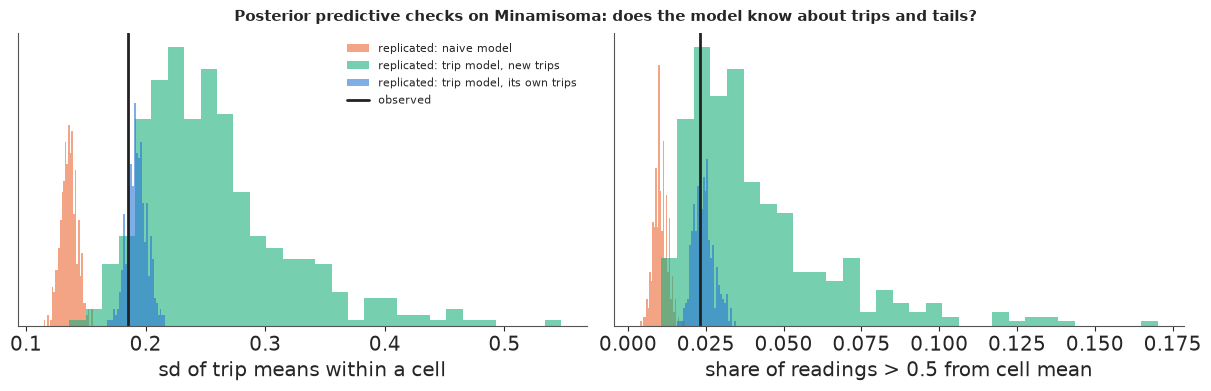

In [8]:
def trip_spread_and_tails(y):
    """(draws, obs) -> two statistics per draw: the typical sd of trip means within a cell, and the share
    of readings more than 0.5 (log) from their cell mean."""
    y = np.atleast_2d(y)
    key = cell_idx * len(trips) + trip_idx
    _, grp = np.unique(key, return_inverse=True)
    G = grp.max() + 1
    gcell = np.zeros(G, int)
    gcell[grp] = cell_idx
    out = []
    for yy in y:
        gm = np.bincount(grp, yy, G) / np.bincount(grp, None, G)
        cm = np.bincount(cell_idx, yy) / np.bincount(cell_idx)
        n_g = np.bincount(gcell, None, len(nb_cells))
        dev2 = np.bincount(gcell, (gm - cm[gcell]) ** 2, len(nb_cells))
        ok = n_g >= 2
        out.append((np.median(np.sqrt(dev2[ok] / (n_g[ok] - 1))), np.mean(np.abs(yy - cm[cell_idx]) > 0.5)))
    return np.array(out)


obs_stat = trip_spread_and_tails(fit_rows.ly.to_numpy())[0]
rep = {}
for name, m in [("naive", m_naive), ("trips", m_trip)]:
    with m:
        pp = pm.sample_posterior_predictive(fits[name].isel(draw=slice(None, None, 10)), random_seed=RANDOM_SEED,
                                            progressbar=False)
    rep[name] = trip_spread_and_tails(pp.posterior_predictive["y"].values.reshape(-1, len(fit_rows)))

# a mixed predictive: the same field, but every trip replaced by a new one, d_new ~ N(mu0, tau)
th = az.extract(fits["trips"], var_names=["mu0", "tau", "sigma", "nu", "f"]).isel(sample=slice(None, None, 10))
pp_rng = np.random.default_rng(RANDOM_SEED)
S_ = th.sizes["sample"]
d_new = th["mu0"].values[:, None] + th["tau"].values[:, None] * pp_rng.standard_normal((S_, len(trips)))
y_new = (d_new[:, trip_idx] + th["f"].values.T[:, cell_idx]
         + th["sigma"].values[:, None] * pp_rng.standard_t(th["nu"].values[:, None], (S_, len(fit_rows))))
rep["new trips"] = trip_spread_and_tails(y_new)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for k, (ax, lab) in enumerate(zip(axes, ["sd of trip means within a cell", "share of readings > 0.5 from cell mean"])):
    for name, c in [("naive", ORANGE), ("new trips", AQUA), ("trips", BLUE)]:
        lab_ = {"naive": "naive model", "trips": "trip model, its own trips",
                "new trips": "trip model, new trips"}[name]
        ax.hist(rep[name][:, k], bins=30, color=c, alpha=0.6, label=f"replicated: {lab_}")
    ax.axvline(obs_stat[k], color=INK, lw=2, label="observed")
    ax.set(xlabel=lab, yticks=[])
axes[0].legend(fontsize=8)
fig.suptitle("Posterior predictive checks on Minamisoma: does the model know about trips and tails?", fontsize=11);
for name in rep:
    print(f"{name:9s}: trip spread {np.round(np.quantile(rep[name][:, 0], [0.05, 0.95]), 3)} (observed "
          f"{obs_stat[0]:.3f}); tail share {np.round(np.quantile(rep[name][:, 1], [0.05, 0.95]), 3)} "
          f"(observed {obs_stat[1]:.3f}); share of replicates at or below the observed trip spread "
          f"{np.mean(rep[name][:, 0] <= obs_stat[0]):.2f}")

The naive model fails both checks. Its replicated trip-to-trip spread (0.13-0.15, 90% interval) sits far
below the observed 0.185: it thinks that two trips to the same cell should agree much better than they do.
Its share of far-off readings (0.7-1.4%) is below the observed 2.3%: normal tails are too thin. The trip
model, replicating readings from its own fitted trips (blue), reproduces both (0.18-0.21 and 2.0-3.1%). That
pass is partly in sample, though: the fitted trip offsets were chosen to explain exactly these trips, so the
within-cell spread of trip means comes back almost by construction.

The harder version (aqua) keeps the field and replaces every trip by a **new** one, drawn from $\mathcal
N(\mu_0, \tau)$. That is the situation the survey will face: a reading from a trip the model has never seen.
The tail share still passes (1.7-9%). The trip spread now runs from 0.18 to 0.39, and the observed 0.185 is
at its low edge: only 7% of replicates are as small. Trips that drove the same cells agree better than a
normal population of trips with sd 0.27 would say, which suggests that $\tau$ is pulled up by a few odd
trips (a device that read low all day) while a typical pair agrees better. The model's noise is therefore,
if anything, **pessimistic**. For a survey that is the safe side, and we will meet it again in Iitate. The
naive model fails in the dangerous direction: a team that trusted it would treat one reading as worth more
than it is and would be fooled by the first trip that reads high.

## D · What will the survey face?

From the trip model we borrow everything the survey needs to believe before it starts. A single reading at a
stop comes from an unknown trip and has error $d_k - \mu_0 + \varepsilon$. We simulate that sum from the
posterior and summarise it by a Student-t with matched shape, which is what the online belief will use.

In [9]:
post = az.extract(fits["trips"], var_names=["mu0", "ell", "eta", "kap", "sigma", "tau", "nu"])
ELL = float(post["ell"].median())
ETA_NB = float(np.exp(np.median(np.log(post["eta"].values[np.abs(np.log(post["ell"].values / ELL)) < 0.1]))))
KAP = float(post["kap"].median())
M0 = float(post["mu0"].mean())
S0 = 1.0  # a new district's level is not the neighbour's: a factor e either way
sim_rng = np.random.default_rng(1)
k = sim_rng.integers(0, post.sizes["sample"], 200_000)
err = (sim_rng.normal(0, 1, 200_000) * post["tau"].values[k]
       + post["sigma"].values[k] * sim_rng.standard_t(post["nu"].values[k]))
NU_A, _, S_A = stats.t.fit(err, floc=0)
NV0 = S_A**2 * NU_A / (NU_A - 2)  # variance of one reading's error
print(f"borrowed from Minamisoma: lengthscale {ELL:.2f} km, amplitude {ETA_NB:.2f} (at that lengthscale), "
      f"cell scatter {KAP:.3f}, level {M0:.2f} "
      f"({np.exp(M0) / CPM_PER_USVH:.2f} uSv/h)")
print(f"error of one reading from an unknown trip (trip offset + within-trip noise): Student-t with "
      f"nu = {NU_A:.1f}, scale {S_A:.3f}  (sd {np.sqrt(NV0):.2f}: a factor {np.exp(np.sqrt(NV0)):.2f})")
print(f"log-amplitude in Minamisoma: posterior sd {float(np.log(post['eta']).std()):.2f}")

borrowed from Minamisoma: lengthscale 5.31 km, amplitude 0.72 (at that lengthscale), cell scatter 0.094, level 5.01 (0.45 uSv/h)
error of one reading from an unknown trip (trip offset + within-trip noise): Student-t with nu = 9.5, scale 0.282  (sd 0.32: a factor 1.37)
log-amplitude in Minamisoma: posterior sd 0.30


The borrowed belief: a field with lengthscale about 5.3 km and amplitude about 0.72 on the log scale, a cell
scatter of about 0.09, and a level near 0.45 uSv/h. One reading has an error with sd 0.32, a factor of about
1.4 either way, and tails close to normal (the trip offset, which is normal, dominates the heavy-tailed
residual).

Iitate is not Minamisoma, and we say so in two places. Its level is higher, so the survey's prior for the
level has an sd of 1 on the log scale, a factor of $e$ either way. Its amplitude may differ too:
Minamisoma's posterior sd of $\log\eta$ is about 0.3, and a different district deserves at least that much
doubt, so the survey keeps a **grid of amplitudes** with a prior sd of 0.5 on $\log \eta$ and learns which
one fits as readings come in (section E).

Now the replay world. Iitate's survey cells are the cells with at least 10 readings on at least 2 days in
the season, so that revealing one reading never reveals the truth. Travel is along roads: two cells are
linked when their centres are at most 550 m apart (diagonal neighbours and small gaps in the GPS track), and
distances are shortest paths over all 1,617 cells driven in 2011-13. The **truth** of a cell is its median
after removing trip offsets, estimated by alternating medians over cells and trips on all the season's
readings (a median polish, with the median trip at zero). The truth uses every reading; a survey sees one
per stop.

Iitate, Apr-Nov 2012: 24,030 readings from 24 logs; 346 cells with >= 10 readings on >= 2 days (1617 road cells driven in 2011-13); road distances up to 31 km
trip offsets: [-0.49 -0.21  0.    0.1   0.17]
cells above 3.8 uSv/h: 21 (6.1%); five hottest (uSv/h): [12.4  9.6  8.9  8.7  8.7], readings [482  16  24  32  13]
one revealed reading minus the truth, log: 5/25/50/75/95% = [-0.36 -0.11 -0.    0.1   0.25]
cells within 0.5 km of the hottest: 4, of them hot 4, truth [8.7 9.6 8.7] uSv/h; the hottest cell's 482 readings: 475 from log 10868 over 46 minutes


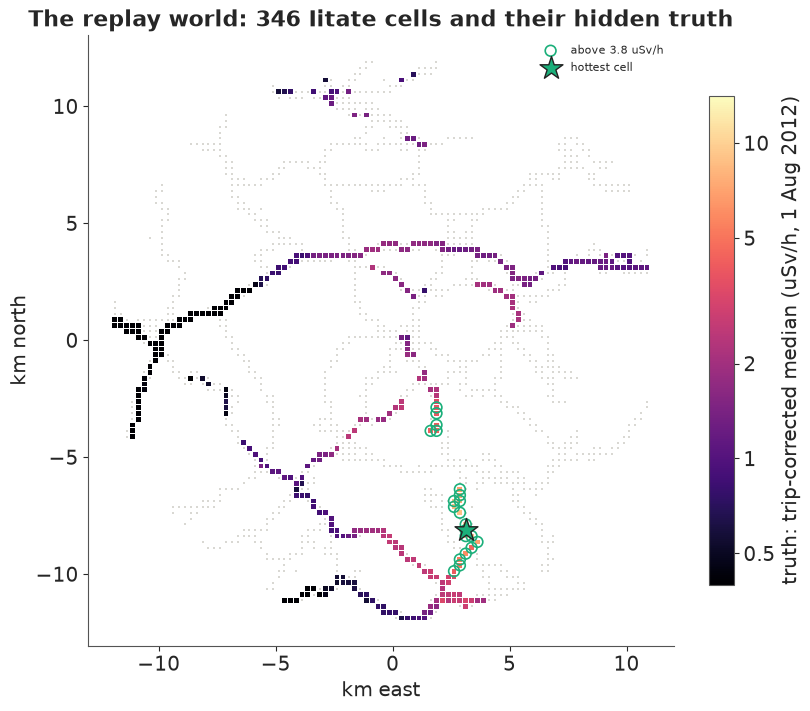

In [10]:
ii = df[df.district == "Iitate"]
road = ii.groupby(["ix", "iy"]).size().reset_index()[["ix", "iy"]]
xy_road = (road.to_numpy() + 0.5) * CELL
dd = np.sqrt(((xy_road[:, None] - xy_road[None]) ** 2).sum(-1))
D_road = dijkstra(csr_matrix(np.where((dd > 0) & (dd <= 0.55), dd, 0)), directed=False)  # km along the network

sv = ii[(ii.t >= WIN[0]) & (ii.t < WIN[1])].copy()
g = sv.groupby(["ix", "iy"])
cells = g.agg(n=("cpm", "size"), days=("day", "nunique")).reset_index()
cells = cells[(cells.n >= 10) & (cells.days >= 2)].reset_index(drop=True)
cells["cell"] = np.arange(len(cells))
sv = sv.merge(cells[["ix", "iy", "cell"]], on=["ix", "iy"])
N = len(cells)
key = {kk: i for i, kk in enumerate(zip(road.ix, road.iy))}
D = D_road[np.ix_(*[[key[kk] for kk in zip(cells.ix, cells.iy)]] * 2)]
xy = (cells[["ix", "iy"]].to_numpy() + 0.5) * CELL

# the truth the survey never sees: cell + trip medians, alternated to convergence
truth = sv.groupby("cell").ly.median().to_numpy()
for _ in range(30):
    trip_off = (sv.ly - truth[sv.cell]).groupby(sv.import_id).median()
    trip_off -= trip_off.median()
    truth = (sv.ly - trip_off.loc[sv.import_id].to_numpy()).groupby(sv.cell).median().to_numpy()
pool = [sv.ly.to_numpy()[sv.cell.to_numpy() == j] for j in range(N)]
HOT = truth > THR
top = np.argsort(truth)[::-1][:5]
rev_err = np.concatenate([p - truth[j] for j, p in enumerate(pool)])
print(f"Iitate, Apr-Nov 2012: {len(sv):,} readings from {sv.import_id.nunique()} logs; {N} cells with >= 10 readings "
      f"on >= 2 days ({len(road)} road cells driven in 2011-13); road distances up to {D.max():.0f} km")
print(f"trip offsets: {np.round(np.quantile(trip_off, [0, 0.1, 0.5, 0.9, 1]), 2)}")
print(f"cells above {THR_USVH} uSv/h: {HOT.sum()} ({HOT.mean():.1%}); five hottest (uSv/h): "
      f"{np.round(np.exp(truth[top]) / CPM_PER_USVH, 1)}, readings {cells.n.to_numpy()[top]}")
print(f"one revealed reading minus the truth, log: 5/25/50/75/95% = "
      f"{np.round(np.quantile(rev_err, [.05, .25, .5, .75, .95]), 2)}")
near_top = D[top[0]] <= 0.5
in_top = sv[sv.cell == top[0]]
big_log = in_top.import_id.value_counts()
t_big = in_top[in_top.import_id == big_log.index[0]].t
print(f"cells within 0.5 km of the hottest: {near_top.sum()}, of them hot {np.sum(near_top & HOT)}, "
      f"truth {np.round(np.exp(truth[near_top & (np.arange(N) != top[0])]) / CPM_PER_USVH, 1)} uSv/h; the hottest "
      f"cell's {len(in_top)} readings: {big_log.iloc[0]} from log {big_log.index[0]} over "
      f"{(t_big.max() - t_big.min()).total_seconds() / 60:.0f} minutes")

fig, ax = plt.subplots(figsize=(8.5, 7))
ax.scatter(xy_road[:, 0], xy_road[:, 1], s=4, color=LIGHT, marker="s", lw=0)
sc = ax.scatter(xy[:, 0], xy[:, 1], c=np.log10(np.exp(truth) / CPM_PER_USVH), s=12, marker="s", cmap="magma",
                vmin=-0.4, vmax=1.15, lw=0)
ax.scatter(xy[HOT, 0], xy[HOT, 1], s=60, facecolor="none", edgecolor=AQUA, lw=1.2, label=f"above {THR_USVH} uSv/h")
ax.scatter(*xy[top[0]], marker="*", s=300, color=AQUA, edgecolor=INK, label="hottest cell")
cb = fig.colorbar(sc, ax=ax, shrink=0.8)
cb.set_ticks(np.log10([0.5, 1, 2, 5, 10]), labels=["0.5", "1", "2", "5", "10"])
cb.set_label("truth: trip-corrected median (uSv/h, 1 Aug 2012)")
ax.set(aspect=1, xlabel="km east", ylabel="km north", title=f"The replay world: {N} Iitate cells and their hidden truth")
ax.legend(fontsize=8, loc="upper right");

The survey district has **346 cells** reachable on roads up to 31 km apart, and **21 of them (6%) are above
3.8 uSv/h**, all in the south: a stretch of road about 3.5 km long near (3, -8) km and a shorter one near
(2, -3.5). The hottest cell, at 12.4 uSv/h, is one where a volunteer parked: 475 of its 482 readings come
from one log (10868) over 46 minutes. Its neighbours read 8.7-9.6. So "the hotspot" is really a short hot
stretch with one very hot point, and we score a survey as having **found** it when its declared hotspot is
within 0.5 km of road of the hottest cell, which takes in four cells, all of them hot. One consequence of
the parked log: a survey that stops at that cell twice draws two readings from the same 46 minutes, which
agree more closely than two trips would. The belief treats them as independent, but with a borrowed noise sd
of 0.32 it gives each one little weight, so the double count makes it only a little too sure, and only there.

Iitate's trips agree with each other better than Minamisoma's: offsets run from -0.49 to +0.17, with 80%
between -0.21 and +0.10. One revealed reading is within about 0.10 of the truth half the time, and 90% of
the time within -0.36 to +0.25. The borrowed noise (sd 0.32) is therefore **pessimistic** for Iitate, as the
mixed predictive check hinted. That is the safe direction to be wrong in - the belief will be too cautious
rather than too sure - and we leave it, because a real team would not know it in advance.

## E · What does the team believe after each stop?

The belief is a Gaussian process over the 346 cells. With $n$ readings $y$ at cells $o$, prior mean $m_0$
and prior covariance

$$K = \eta^2\, \text{Mat\'ern}_{5/2}(\ell) + \kappa^2 I + s_0^2 \mathbf 1 \mathbf 1^\top$$

(the last term is the unknown level, $s_0 = 1$), the posterior is the usual one,

$$\mu = m_0 + K_{\cdot o}(K_{oo} + R)^{-1}(y - m_0), \qquad
v = \operatorname{diag}\!\big(K - K_{\cdot o}(K_{oo} + R)^{-1}K_{o\cdot}\big),$$

except that the reading errors are Student-t, so the noise matrix $R$ is not fixed. A Student-t is a normal
whose precision is random, and the EM algorithm for it (Lange et al. 1989) alternates two steps: given the
field, each reading gets a noise variance $R_{ii} = (\nu s^2 + r_i^2 + v_i)/(\nu + 1)$ from its residual
$r_i$; given those, the field is the normal posterior above. A reading far from what its neighbours say gets
a large variance and little weight. We run two EM steps per stop, warm-started from the previous stop, which
is plenty.

The amplitude is learned by keeping nine copies of the belief, one per amplitude on a grid, weighting each
by its prior and its marginal likelihood of the readings so far, and mixing. The probability that a cell is
above the threshold is then $P_j = \sum_a w_a\, \Phi\big((\mu_{aj} - \log 1269)/\sqrt{v_{aj}}\big)$.
Thompson sampling needs whole-field draws, which Matheron's rule gives cheaply (Wilson et al. 2020): draw a
field from the prior, draw noise for each reading, and correct the field by the posterior update of the
difference. The lookahead policy needs the expected decision loss after one more reading at each candidate,
which has a closed form given the reading and one 7-point Gauss-Hermite sum over it.

In [11]:
R = np.sqrt(((xy[:, None] - xy[None]) ** 2).sum(-1)) / ELL
MATERN = (1 + np.sqrt(5) * R + 5 / 3 * R**2) * np.exp(-np.sqrt(5) * R)
GH_X, GH_W = np.polynomial.hermite_e.hermegauss(7)
GH_W = GH_W / GH_W.sum()
LOG_ETA_SD = 0.5  # how much a district's amplitude may differ from its neighbour's


class Belief:
    """GP belief over the N cells, mixed over a grid of amplitudes; Student-t readings via reweighting."""

    def __init__(self, etas, log_prior):
        self.etas, self.log_prior = np.asarray(etas), np.asarray(log_prior)
        self.K = [e**2 * MATERN + KAP**2 * np.eye(N) + S0**2 for e in self.etas]
        self.nv = [np.zeros(0) for _ in self.etas]
        self.Lp = [np.linalg.cholesky(K + 1e-6 * np.eye(N)) for K in self.K]
        self.update([], [])

    def _one(self, k, obs, y):
        K = self.K[k]
        if len(obs) == 0:
            self.nv[k] = np.zeros(0)
            return np.full(N, M0), np.diag(K).copy(), None, 0.0
        nv = np.r_[self.nv[k][: len(obs) - 1], np.full(len(obs) - len(self.nv[k][: len(obs) - 1]), NV0)]
        for _ in range(2):  # EM for the Student-t, warm-started: each reading's weight from its residual
            Lc = np.linalg.cholesky(K[np.ix_(obs, obs)] + np.diag(nv))
            alpha = np.linalg.solve(Lc.T, np.linalg.solve(Lc, y - M0))
            mu = M0 + K[:, obs] @ alpha
            V = np.linalg.solve(Lc, K[:, obs].T)
            var = np.maximum(np.diag(K) - (V**2).sum(0), 1e-9)
            nv = (NU_A * S_A**2 + (y - mu[obs]) ** 2 + var[obs]) / (NU_A + 1)
        self.nv[k] = nv
        loglik = -0.5 * alpha @ (y - M0) - np.log(np.diag(Lc)).sum()
        return mu, var, (Lc, V, nv), loglik

    def update(self, obs, y):
        self.obs, self.y = np.asarray(obs, int), np.asarray(y, float)
        self.comp = [self._one(k, self.obs, self.y) for k in range(len(self.K))]
        lw = self.log_prior + np.array([c[3] for c in self.comp])
        self.w = np.exp(lw - lw.max())
        self.w /= self.w.sum()
        mus, vs = np.array([c[0] for c in self.comp]), np.array([c[1] for c in self.comp])
        self.mu = self.w @ mus
        self.var = self.w @ (vs + mus**2) - self.mu**2
        self.p = self.w @ ndtr((mus - THR) / np.sqrt(vs))  # P(cell above the threshold)

    def draw(self, rng, n=1):
        """Joint draws of the field (Matheron's rule: a prior draw corrected by the data)."""
        out = np.empty((n, N))
        for i in range(n):
            k = rng.choice(len(self.etas), p=self.w)
            f = M0 + self.Lp[k] @ rng.standard_normal(N)
            if len(self.obs):
                Lc, V, nv = self.comp[k][2]
                e = rng.standard_normal(len(self.obs)) * np.sqrt(nv)
                f = f + self.K[k][:, self.obs] @ np.linalg.solve(Lc.T, np.linalg.solve(Lc, self.y - f[self.obs] - e))
            out[i] = f
        return out

    def expected_loss_after(self, cand, cost):
        """Expected closure loss over all cells after one more reading at each candidate (one-step lookahead)."""
        tot = np.zeros(len(cand))
        for k, (mu, var, aux, _) in enumerate(self.comp):
            if self.w[k] < 0.01:
                continue
            K = self.K[k]
            C = K[:, cand] if aux is None else K[:, cand] - aux[1].T @ np.linalg.solve(aux[0], K[np.ix_(self.obs, cand)])
            s_y = np.sqrt(var[cand] + NV0)
            sd_new = np.sqrt(np.maximum(var[:, None] - (C / s_y) ** 2, 1e-9))
            for gx, gw in zip(GH_X, GH_W):
                p = ndtr((mu[:, None] + C / s_y * gx - THR) / sd_new)
                tot += self.w[k] * gw * np.minimum(cost * p, 1 - p).sum(0)
        return tot


ETAS = ETA_NB * np.exp(np.linspace(-0.75, 1.25, 9))
fused = Belief(ETAS, stats.norm.logpdf(np.log(ETAS), np.log(ETA_NB), LOG_ETA_SD))
borrowed = Belief([ETA_NB], [0.0])
print("amplitude grid:", np.round(ETAS, 2))
print("prior weights: ", np.round(fused.w, 2))

amplitude grid: [0.34 0.44 0.56 0.72 0.93 1.19 1.53 1.97 2.53]
prior weights:  [0.07 0.13 0.18 0.21 0.18 0.13 0.07 0.03 0.01]


The amplitude grid runs from about 0.3 to 2.5, with more room above the borrowed 0.72 than below, and prior
weights centred on 0.72.

The decision the team must make is a closure list. Leaving a hot cell open (people drive and work there) is
worse than closing a safe one (a detour, a sign), and we take a missed hot cell to cost **nine** times a
needlessly closed one. A cell should then be closed when $P_j \ge 1/(1+9) = 0.1$. The **closure loss** of a
survey is $9 \times$ (hot cells left open) + (safe cells closed).

The policies are:

- **grid**: a planner's fixed design, 40 points spread over the road cells by k-means (a different random
  layout for each replay, as a planner does not know where the hotspot is), visited in a nearest-neighbour
  tour. The grid obeys the same 4 km rule as everyone else: when its next point is further away, the car
  stops on the way, at the reachable cell closest to that point by road, and that stop counts as one of the
  40;
- **random**: any reachable cell;
- **UCB nearby**: among the cells within 4 km, the one with the largest $\mu + 2\sqrt v$;
- **UCB**: the cell with the largest $\mu + 2\sqrt v$ anywhere; if it is too far, drive toward it and stop
  at the reachable cell closest to it by road;
- **Thompson**: the hottest cell of one posterior draw, approached the same way;
- **lookahead**: the reachable cell that most lowers the expected closure loss after one more reading;
- **grid then UCB** and **grid then UCB nearby**: 20 stops on a coarser 20-point grid (points not reached by
  then are dropped), then 20 adaptive stops;
- **climb then bound**: 20 stops of UCB nearby, then 20 stops of lookahead.

The first two use no model of the decision at all. UCB and Thompson are aimed at the **hotspot**; the
lookahead is aimed at the **closure list**. Every policy uses the same belief, and every survey ends with
the same answers: a declared hotspot and a closure list. The declared hotspot is the cell with the highest
posterior mean. Because that rule smooths, we also score two others: the cell that is hottest most often in
200 posterior draws of the whole field, and, with no model at all, the cell that gave the single highest
reading.

In [12]:
HOP, STOPS, COST = 4.0, 40, 9.0  # km between stops at most; stops in the day; missed hot cell = 9 x closed safe cell
def grid_design(n_stops, seed):
    """A survey planner's even spread of stops: k-means centres over the cells, snapped to the nearest cell.
    The seed plays the part of where the planner happens to lay the grid."""
    cent, _ = kmeans2(xy, n_stops, seed=seed, minit="++")
    return np.unique([np.argmin(((xy - c) ** 2).sum(1)) for c in cent])


def route_through(stops, start):
    """Greedy nearest-neighbour tour of fixed stops, along the road network."""
    left, route, cur = list(stops), [], start
    while left:
        j = int(np.argmin(D[cur, left]))
        cur = left.pop(j)
        route.append(cur)
    return route


def toward(cur, target, reach):
    return target if D[cur, target] <= HOP else reach[np.argmin(D[reach, target])]


def choose(policy, cur, B, rng, ok):
    reach = np.flatnonzero((D[cur] <= HOP) & ok)
    if policy == "random":
        return rng.choice(reach)
    ucb = B.mu + 2.0 * np.sqrt(B.var)
    if policy in ("UCB nearby", "grid then UCB nearby"):
        return reach[np.argmax(ucb[reach])]
    if policy in ("UCB", "grid then UCB"):
        return toward(cur, np.argmax(np.where(ok, ucb, -np.inf)), reach)
    if policy == "Thompson":
        return toward(cur, np.argmax(np.where(ok, B.draw(rng)[0], -np.inf)), reach)
    if policy == "lookahead":
        return reach[np.argmin(B.expected_loss_after(reach, COST))]
    raise ValueError(policy)


def survey(policy, start, seed, B, stops=STOPS, keep_history=False):
    rng = np.random.default_rng(seed)
    left = [list(rng.permutation(len(p))) for p in pool]  # each cell's readings, revealed without replacement
    route = (route_through(grid_design(stops, seed), start) if policy == "grid" else
             route_through(grid_design(stops // 2, seed), start) if policy.startswith("grid then") else [])
    n_planned, reached = len(route), 0
    obs, y, cur, km, hist = [], [], start, 0.0, []
    B.update(obs, y)
    for t in range(stops):
        ok = np.array([len(l) > 0 for l in left])
        if policy.startswith("grid then") and t == stops // 2:
            route = []  # half the day is gone: drop any grid points not yet reached, and adapt
        while route and not ok[route[0]]:
            route.pop(0)
        if route:  # a fixed design obeys the same 4 km rule: a far target costs stops on the way
            reach = np.flatnonzero((D[cur] <= HOP) & ok)
            nxt = toward(cur, route[0], reach)
            if nxt == route[0]:
                route.pop(0)
                reached += 1
        elif policy == "grid":
            break  # every planned point visited
        else:
            now = ("UCB nearby" if t < stops // 2 else "lookahead") if policy == "climb then bound" else policy
            nxt = choose(now, cur, B, rng, ok)
        km += D[cur, nxt]
        cur = nxt
        obs.append(cur)
        y.append(pool[cur][left[cur].pop()])
        B.update(obs, y)
        while route and not left[route[0]]:
            route.pop(0)  # a planned cell whose readings are used up
        last = t == stops - 1 or (policy == "grid" and not route)
        if keep_history or last:
            hot = int(np.argmax(B.mu))
            if last:  # the cell most often hottest in 200 posterior draws of the whole field
                pmax_hot = np.bincount(B.draw(rng, 200).argmax(1), minlength=N).argmax()
            hist.append(dict(stop=t + 1, found=D[hot, top[0]] <= 0.5, share_of_max=np.exp(truth[hot] - truth[top[0]]),
                             raw_found=D[obs[int(np.argmax(y))], top[0]] <= 0.5,
                             pmax_found=D[pmax_hot, top[0]] <= 0.5 if last else np.nan,
                             planned=n_planned, reached=reached, n_stops=t + 1,
                             missed=int(np.sum((B.p < 1 / (1 + COST)) & HOT)),
                             closed_safe=int(np.sum((B.p >= 1 / (1 + COST)) & ~HOT)),
                             raw_missed=int(np.sum(HOT & ~np.isin(np.arange(N), np.array(obs)[np.array(y) > THR]))),
                             mean_err=abs(B.mu.mean() - truth.mean()),
                             cover90=np.mean(np.abs(truth - B.mu) < 1.645 * np.sqrt(B.var)), km=km, eta=B.w @ B.etas))
    return pd.DataFrame(hist), obs, y

Before the comparison, one survey up close. A grid survey from the western road plans 40 points, reaches 35
of them in its 40 stops (the other five stops are on the way to a far point) and drives 89 km. The weights
on the amplitude grid move from the prior to the borrowed 0.72 (weight 0.42) and the next value up, 0.93
(weight 0.41), an average of 0.84: Iitate's readings ask for a field a little rougher than Minamisoma's, but
not much. That is worth knowing, and it costs nothing to check.

grid survey from cell 68: 40 planned points, 35 reached, 40 stops, 89 km
posterior weights on the amplitude grid: [0.   0.   0.08 0.42 0.41 0.08 0.   0.   0.  ]  -> mean amplitude 0.84
readings alone  : close   1 cells,  1 hot and  0 safe; hot cells left open 20; loss 180
1 km buffer     : close   8 cells,  4 hot and  4 safe; hot cells left open 17; loss 157
inverse distance: close   2 cells,  2 hot and  0 safe; hot cells left open 19; loss 171
borrowed belief : close  28 cells, 21 hot and  7 safe; hot cells left open  0; loss 7
fused belief    : close  30 cells, 21 hot and  9 safe; hot cells left open  0; loss 9
fused P(above 3.8) on the hot cells of the long stretch (south of y = -5): [0.33 0.66 0.7 ] (min, median, max over 16 cells)
fused P(above 3.8) on the hot cells of the short group: [0.25 0.42 0.47] (min, median, max over 5 cells)
cells on which the borrowed and fused lists differ: 2
borrowed: 90% intervals cover the truth in 0.92 of cells
fused: 90% intervals cover the truth i

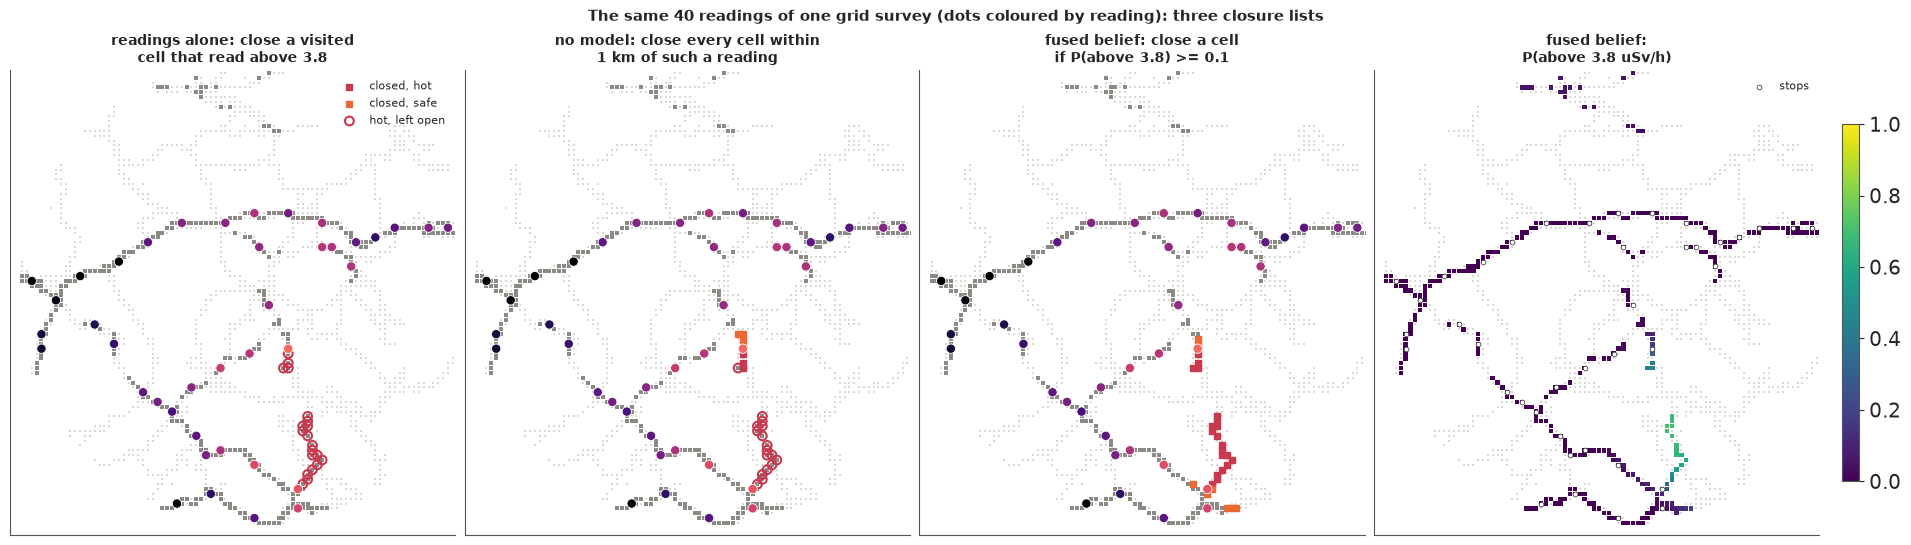

In [13]:
start0 = int(np.argmin(((xy - np.array([-6.0, 2.0])) ** 2).sum(1)))  # a start on the western road
res_b, obs_b, y_b = survey("grid", start0, 7, borrowed)
p_borrowed, mu_borrowed = borrowed.p.copy(), borrowed.mu.copy()
res_f, obs_f, y_f = survey("grid", start0, 7, fused)
print(f"grid survey from cell {start0}: {res_f.planned.iloc[-1]} planned points, {res_f.reached.iloc[-1]} reached, "
      f"{len(obs_f)} stops, {res_f.km.iloc[-1]:.0f} km")
print("posterior weights on the amplitude grid:", np.round(fused.w, 2), f" -> mean amplitude {fused.w @ ETAS:.2f}")
yv, ov = np.array(y_f), np.array(obs_f)
rules = {
    "readings alone": np.isin(np.arange(N), ov[yv > THR]),
    "1 km buffer": (D[:, ov[yv > THR]] <= 1.0).any(1) if (yv > THR).any() else np.zeros(N, bool),
    "inverse distance": ((1 / (D[:, ov] + 0.1) ** 2) @ yv) / (1 / (D[:, ov] + 0.1) ** 2).sum(1) > THR,
    "borrowed belief": p_borrowed >= 1 / (1 + COST),
    "fused belief": fused.p >= 1 / (1 + COST),
}
for name, closed in rules.items():
    print(f"{name:16s}: close {closed.sum():3d} cells, {np.sum(closed & HOT):2d} hot and {np.sum(closed & ~HOT):2d} safe; "
          f"hot cells left open {np.sum(~closed & HOT):2d}; loss {COST * np.sum(~closed & HOT) + np.sum(closed & ~HOT):.0f}")
south = xy[:, 1] < -5
for lab_, grp_ in [("long stretch (south of y = -5)", HOT & south), ("short group", HOT & ~south)]:
    print(f"fused P(above 3.8) on the hot cells of the {lab_}: {np.round(np.quantile(fused.p[grp_], [0, 0.5, 1]), 2)}"
          f" (min, median, max over {grp_.sum()} cells)")
print(f"cells on which the borrowed and fused lists differ: {np.sum(rules['borrowed belief'] != rules['fused belief'])}")
for name, (mu_, B_) in [("borrowed", (mu_borrowed, borrowed)), ("fused", (fused.mu, fused))]:
    print(f"{name}: 90% intervals cover the truth in {np.mean(np.abs(truth - mu_) < 1.645 * np.sqrt(B_.var)):.2f} of cells")

fig, axes = plt.subplots(1, 4, figsize=(19, 5.4))
panels = [("readings alone: close a visited\ncell that read above 3.8", rules["readings alone"]),
          ("no model: close every cell within\n1 km of such a reading", rules["1 km buffer"]),
          ("fused belief: close a cell\nif P(above 3.8) >= 0.1", rules["fused belief"])]
for ax, (title, closed) in zip(axes[:3], panels):
    ax.scatter(xy_road[:, 0], xy_road[:, 1], s=3, color=LIGHT, marker="s", lw=0)
    ax.scatter(xy[:, 0], xy[:, 1], s=6, color=MUTED, marker="s", lw=0)
    ax.scatter(xy[closed & HOT, 0], xy[closed & HOT, 1], s=16, color=RED, marker="s", label="closed, hot")
    ax.scatter(xy[closed & ~HOT, 0], xy[closed & ~HOT, 1], s=16, color=ORANGE, marker="s", label="closed, safe")
    ax.scatter(xy[~closed & HOT, 0], xy[~closed & HOT, 1], s=40, facecolor="none", edgecolor=RED, lw=1.5,
               label="hot, left open")
    ax.scatter(xy[obs_f, 0], xy[obs_f, 1], c=np.array(y_f), cmap="magma", s=45, edgecolor="white", lw=0.6,
               vmin=np.log(0.3 * CPM_PER_USVH), vmax=np.log(14 * CPM_PER_USVH), zorder=5)
    ax.set(aspect=1, xticks=[], yticks=[], xlim=(-12.5, 10.5), ylim=(-12.5, 11.5))
    ax.set_title(title, fontsize=10)
axes[0].legend(fontsize=8, loc="upper right")
ax = axes[3]
ax.scatter(xy_road[:, 0], xy_road[:, 1], s=3, color=LIGHT, marker="s", lw=0)
sc = ax.scatter(xy[:, 0], xy[:, 1], c=fused.p, s=10, marker="s", cmap="viridis", vmin=0, vmax=1, lw=0)
ax.scatter(xy[obs_f, 0], xy[obs_f, 1], s=12, color="white", edgecolor=INK, lw=0.5, zorder=5, label="stops")
ax.set(aspect=1, xticks=[], yticks=[], xlim=(-12.5, 10.5), ylim=(-12.5, 11.5))
ax.set_title("fused belief:\nP(above 3.8 uSv/h)", fontsize=10)
fig.colorbar(sc, ax=ax, shrink=0.75)
ax.legend(fontsize=8, loc="upper right")
fig.suptitle(f"The same {len(obs_f)} readings of one grid survey (dots coloured by reading): three closure lists", fontsize=11);

The three closure maps are the point of having a model at all, and they show the **fusion of the readings
through the field model changing the answer**. The same 40 readings, read one at a time, close only the
**one** visited cell that read above 3.8 and leave **20 of the 21 hot cells open**: the grid did not stop on
them, and a cell nobody visited cannot be closed by its own reading.

That is an unfair baseline, since it cannot close a cell it did not visit, so we add two that can, without a
model. A field team's rule of thumb, *close everything within 1 km of road of a hot reading*, closes 8
cells, 4 of them hot, and still leaves 17 hot cells open (second panel). Inverse-distance interpolation of
the log readings closes 2 cells and leaves 19 open: it averages the one hot reading with cooler readings
around it and lands below the threshold. Both fail for the same reason. They do not know how far a hot field
extends from one reading, nor how much one reading can be trusted.

The fused belief knows both: the field is smooth over about 5 km, the readings near (3, -8) were high, and a
single reading strays by a factor of about 1.4. It closes **30 cells, all 21 hot ones and 9 safe ones** -
the long hot stretch, the short group north of it, and some safe cells at the stretch's southern end - for a
closure loss of 9 against 157 for the 1 km rule. The right panel shows why: the probability of being above
the threshold is near 0 in the north and west; on the hot cells it is 0.33-0.70 (median 0.66) along the long
stretch and 0.25-0.47 at the short group. The belief is never sure that a cell is hot, but the 9-to-1 costs ask
only for 0.1, and every hot cell clears it. The belief with the borrowed
amplitude closes 28 cells (21 hot, 7 safe); the two lists differ on only 2 cells.

## F · Where should the next stop be?

Now every policy, from 40 random starting cells. Each replay draws its own order of readings within each
cell, the same for all policies (common random numbers), so differences between policies are paired.

In [14]:
N_REP = 40
starts = np.random.default_rng(RANDOM_SEED).choice(N, N_REP, replace=False)
POLICIES = ["grid", "random", "UCB nearby", "UCB", "Thompson", "lookahead", "grid then UCB", "grid then UCB nearby",
            "climb then bound"]
runs, hist_runs = [], []
for pol in POLICIES:
    t0 = time.time()
    for r, s in enumerate(starts):
        h, _, _ = survey(pol, int(s), 1000 + r, fused, keep_history=(pol != "grid"))
        h["policy"], h["rep"] = pol, r
        hist_runs.append(h)
        runs.append(h.iloc[-1].to_dict())
    print(f"{pol:14s} {time.time() - t0:5.1f} s")
final = pd.DataFrame(runs)
final["loss"] = COST * final.missed + final.closed_safe  # the closure decision's loss, in safe-cell units
hist = pd.concat(hist_runs, ignore_index=True)
summary = final.groupby("policy", sort=False).agg(
    found=("found", "mean"), pmax_found=("pmax_found", "mean"), raw_found=("raw_found", "mean"),
    share_of_max=("share_of_max", "mean"), missed=("missed", "mean"), closed_safe=("closed_safe", "mean"),
    loss=("loss", "mean"), mean_err=("mean_err", "mean"), cover90=("cover90", "mean"), km=("km", "mean"),
    eta=("eta", "mean"))
print(summary.round(2))
g_ = final[final.policy == "grid"]
print(f"grid: {g_.planned.mean():.1f} planned points, {g_.reached.mean():.1f} reached in {g_.n_stops.mean():.1f} "
      f"stops (the rest are stops on the way); all reached in {np.mean(g_.reached == g_.planned):.0%} of surveys")

grid             5.3 s


random           5.3 s


UCB nearby       5.3 s


UCB              5.2 s


Thompson         5.5 s


lookahead       19.2 s


grid then UCB    5.3 s


grid then UCB nearby   5.4 s


climb then bound  11.7 s
                      found  pmax_found  raw_found  share_of_max  missed  closed_safe    loss  mean_err  cover90      km   eta
policy                                                                                                                        
grid                   0.15        0.02       0.18          0.55    4.20         8.25   46.05      0.09     0.91   80.44  0.80
random                 0.12        0.05       0.28          0.43    8.72        78.12  156.65      0.26     0.90   84.21  0.89
UCB nearby             0.92        0.92       0.92          0.92    1.68       103.65  118.72      0.18     0.94   56.90  1.10
UCB                    0.45        0.42       0.45          0.60    7.58        77.15  145.32      0.28     0.91   39.48  0.95
Thompson               0.60        0.57       0.75          0.77    2.22        98.70  118.72      0.23     0.94   96.38  1.00
lookahead              0.00        0.00       0.35          0.59    1.35         5.12 

The paired differences between the policies that matter, and the four scores in one picture:

found                  UCB nearby - grid: +0.78 +- 0.07 (paired over 40 starts)
pmax_found             UCB nearby - grid: +0.90 +- 0.05 (paired over 40 starts)
found                  UCB nearby - UCB : +0.47 +- 0.08 (paired over 40 starts)
found        grid then UCB nearby - grid: +0.68 +- 0.07 (paired over 40 starts)
missed                  lookahead - grid: -2.85 +- 0.98 (paired over 40 starts)
closed_safe             lookahead - grid: -3.12 +- 1.66 (paired over 40 starts)
loss                    lookahead - grid: -28.77 +- 8.46 (paired over 40 starts)
loss         grid then UCB nearby - grid: +9.12 +- 8.68 (paired over 40 starts)
mean_err               UCB nearby - grid: +0.09 +- 0.02 (paired over 40 starts)


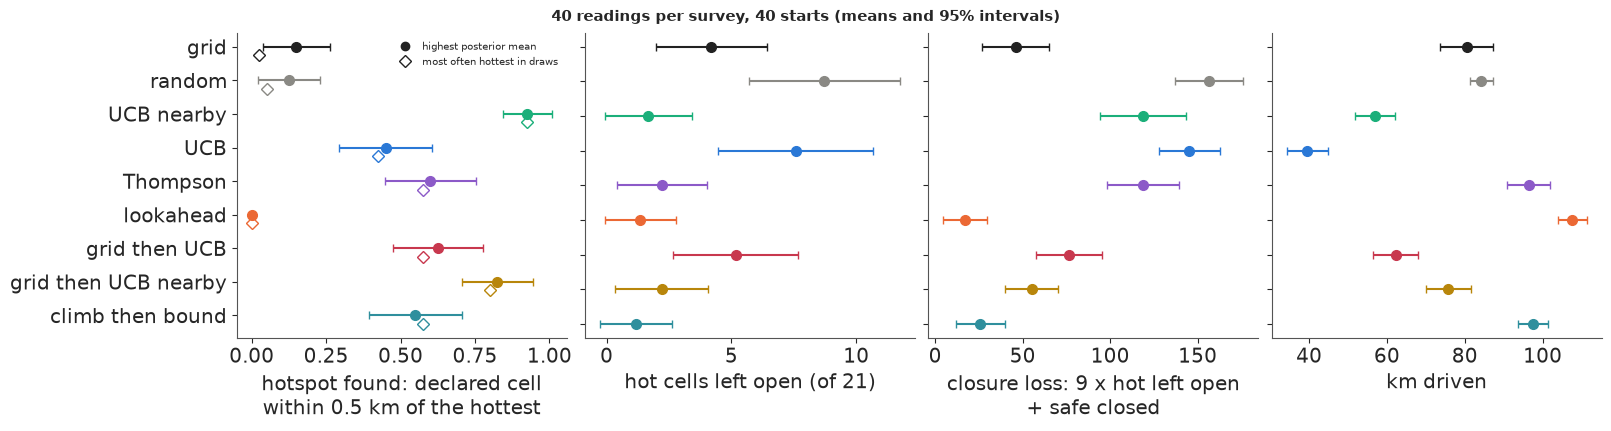

In [15]:
def paired(metric, a, b):
    d = final[final.policy == a].sort_values("rep")[metric].to_numpy().astype(float) - \
        final[final.policy == b].sort_values("rep")[metric].to_numpy().astype(float)
    return d.mean(), d.std(ddof=1) / np.sqrt(len(d))


for metric, a, b in [("found", "UCB nearby", "grid"), ("pmax_found", "UCB nearby", "grid"),
                     ("found", "UCB nearby", "UCB"), ("found", "grid then UCB nearby", "grid"),
                     ("missed", "lookahead", "grid"), ("closed_safe", "lookahead", "grid"), ("loss", "lookahead", "grid"),
                     ("loss", "grid then UCB nearby", "grid"), ("mean_err", "UCB nearby", "grid")]:
    m_, se = paired(metric, a, b)
    print(f"{metric:12s} {a:>20s} - {b:<4s}: {m_:+.2f} +- {se:.2f} (paired over {N_REP} starts)")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
cols = {p: c for p, c in zip(POLICIES, [INK, MUTED, AQUA, BLUE, PURPLE, ORANGE, RED, "#b8860b", "#2f8f9d"])}
for ax, (metric, lab) in zip(axes, [("found", "hotspot found: declared cell\nwithin 0.5 km of the hottest"),
                                    ("missed", f"hot cells left open (of {HOT.sum()})"),
                                    ("loss", f"closure loss: {COST:.0f} x hot left open\n+ safe closed"), ("km", "km driven")]):
    for i, pol in enumerate(POLICIES):
        v = final[final.policy == pol][metric].astype(float)
        se = v.std(ddof=1) / np.sqrt(len(v))
        ax.errorbar(v.mean(), i, xerr=1.96 * se, fmt="o", color=cols[pol], ms=7, capsize=3)
        if metric == "found":  # the other declaration rule: most often hottest in posterior draws
            ax.plot(final[final.policy == pol].pmax_found.mean(), i + 0.25, "D", mfc="none", mec=cols[pol], ms=6)
    if metric == "found":
        ax.plot([], [], "o", color=INK, label="highest posterior mean")
        ax.plot([], [], "D", mfc="none", mec=INK, label="most often hottest in draws")
        ax.legend(fontsize=7, loc="upper right")
    ax.set(yticks=range(len(POLICIES)), yticklabels=POLICIES if ax is axes[0] else [], xlabel=lab)
    ax.invert_yaxis()
fig.suptitle(f"{STOPS} readings per survey, {N_REP} starts (means and 95% intervals)", fontsize=11);

The table above holds the main results, and the paired differences say which gaps are larger than the noise
of 40 replays. Under the 4 km rule the grid never completes its design: on average it reaches about 30 of
its 40 planned points, and the other ten stops are spent on the way to far ones.

**Finding the hotspot.** **UCB nearby** declares a cell within 0.5 km of the hottest in **92%** of surveys,
driving only about 57 km. It climbs: the field is smooth on a scale of kilometres, so the highest upper
bound within reach usually points uphill, and the team follows the gradient to the top. **UCB** that may
head for any cell finds it in 45% (47 points fewer than UCB nearby, paired standard error 8): its target can
be wherever the upper bound is high, including unvisited corners, so fewer of its stops are spent climbing.
**Thompson** sampling, whose draws are wildest exactly where nothing has been measured, finds it in 60%
while driving 96 km. The **grid** finds it in only **15%** of surveys.

Is that last number the grid's fault or the declaration rule's? A posterior-mean argmax smooths, and a
spread design with one lucky reading near the peak could have that reading averaged away. The other two
columns answer it. The grid's single highest reading was within 0.5 km of the hottest cell in 18% of
surveys, hardly more than the 15% it declared: its stops rarely land on the hot point at all, because a
40-point grid over a 31-km network puts a point every couple of kilometres and the hot point is one cell.
Declaring the cell that is hottest most often in posterior draws does worse still for the grid (2%), because
with no readings near the peak the draws put their maxima all over the unvisited south. For UCB nearby all
three rules agree at 92%. The ranking does not depend on the rule.

The lookahead is the instructive exception. Its highest reading was near the hottest cell in 35% of surveys,
but it never declared that cell (0%): it is aimed at cells whose closure is in doubt, which here are the
**edges** of the hot stretch, not its top. The cell it declares is on the hot stretch but worth on average
only 59% of the maximum.

**Bounding the hazard.** Here the order reverses. The **lookahead**, aimed at exactly this loss, leaves 1.4
hot cells open and closes 5 safe ones, a closure loss of 17. The **grid** leaves 4.2 hot cells open and
closes 8 safe ones, a loss of 46; the paired difference is 29 in the lookahead's favour, with a standard
error of 8.5. The hotspot chasers are bad at it in a different way: UCB nearby leaves 1.7 hot cells open but
closes **104** safe ones, UCB leaves 7.6 hot cells open and closes 77, Thompson closes 99.

The reason is the **level** of the field, and it is worth getting right. In a Bayesian analysis, a design
that chooses where to measure from the data seen so far is *ignorable*: the posterior is the same as if the
stops had been fixed in advance, **provided the model is right**. Here it is not quite. One constant level
plus a stationary field with one amplitude cannot hold a sharp hot south and a cool west at the same time. A
grid spreads its readings, so the misfit is shared out. A survey that spends its stops on the hottest road
gives all the weight to the place where the misfit bites: the level is pulled up (the error of the district
mean is 0.18 for UCB nearby against 0.09 for the grid, paired difference 0.09 with standard error 0.02), the
learned amplitude is pushed up too (1.10 against 0.80), and the cautious closure rule then closes the
unvisited roads. The fix is in the model, not in the sampling: a mean that can tilt toward the plume axis,
or a field whose amplitude varies over the district - or, more cheaply, some readings spread over the
district, as the hybrids keep. Random stops are bad at everything: a random walk covers the district thinly
and leaves almost 9 hot cells open.

**Both at once.** The three hybrids trade one job for the other. **Grid then UCB nearby** finds the hotspot
in **82%** of surveys (68 points more than the grid, paired) and leaves 2.2 hot cells open, but closes 35
safe ones: a closure loss of 55, about 9 more than the grid's, with a paired standard error of the same
size, so no clear difference. **Climb then bound** reverses the order of the jobs, climbing first and then
spending the afternoon on the closure decision. It leaves the fewest hot cells open of any policy (1.2) and
closes 15 safe ones, a loss of 26, second only to the lookahead's 17; it finds the hotspot in 55% of
surveys, and the cell it declares is worth on average 72% of the maximum. The morning's climb finds the hot
stretch, and the afternoon's lookahead, spending its stops on the doubtful cells, brings the level back: the
error of the district mean is 0.07, against 0.18 for UCB nearby alone.

Travel matters too. The grid drives about 80 km, UCB nearby 57, while the lookahead, which crosses the
district to wherever a closure is in doubt, drives 108, and climb then bound 98. A team paid by the hour
would weigh that next to the losses.

## G · How does the answer grow with the readings?

The table is a snapshot at 40 stops. The same replays, scored after every stop, show how the answers build
up. The grid cannot be scored that way - a 10-stop grid is a different design from the first 10 stops of a
40-stop grid - so we run grids of 10, 20, 30 and 40 stops separately (20 replays each).

        planned  reached  found  raw_found  pmax_found  missed  closed_safe     km
design                                                                            
10         10.0      3.9    0.1       0.05        0.05   10.80        40.20  23.20
20         20.0     11.6    0.2       0.45        0.10    9.90        16.45  46.63
30         30.0     20.0    0.2       0.30        0.00    4.75        22.20  66.09
40         40.0     29.0    0.1       0.15        0.00    4.20         7.70  78.28


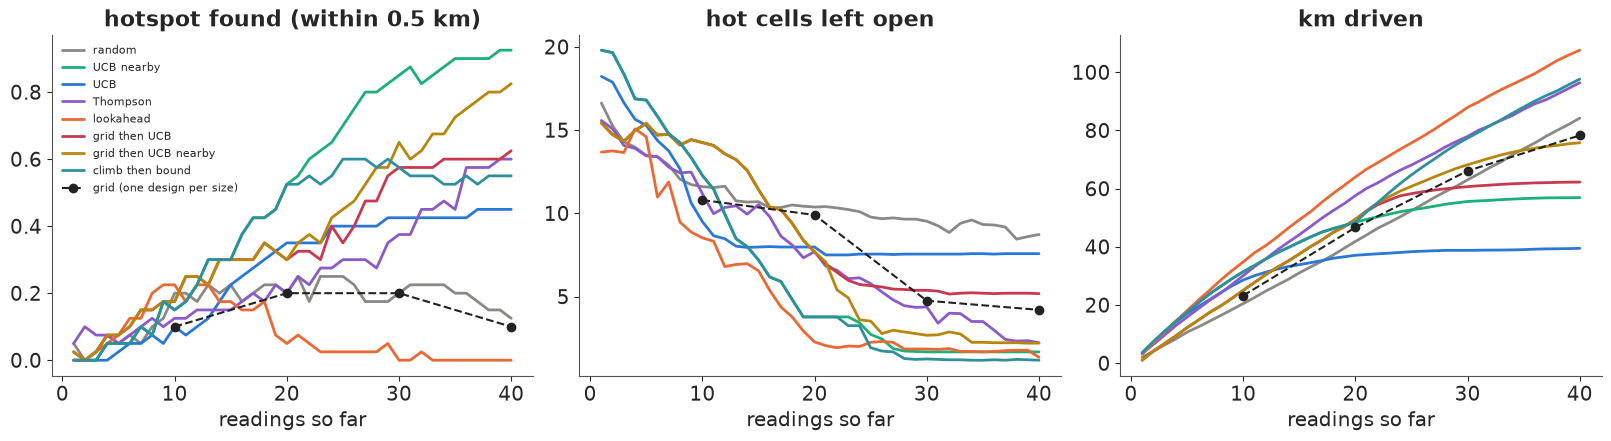

In [16]:
grid_curve = []
for n_stops in (10, 20, 30, 40):
    for r, s in enumerate(starts[:20]):
        h, _, _ = survey("grid", int(s), 1000 + r, fused, stops=n_stops)
        grid_curve.append(dict(design=n_stops, **h.iloc[-1].to_dict()))
grid_curve = pd.DataFrame(grid_curve).groupby("design").mean(numeric_only=True)
curves = hist.groupby(["policy", "stop"]).mean(numeric_only=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, (metric, lab) in zip(axes, [("found", "hotspot found (within 0.5 km)"), ("missed", "hot cells left open"),
                                    ("km", "km driven")]):
    for pol in POLICIES[1:]:
        cc = curves.loc[pol]
        ax.plot(cc.index, cc[metric], color=cols[pol], lw=2, label=pol)
    ax.plot(grid_curve.index, grid_curve[metric], "o--", color=INK, lw=1.5, ms=6, label="grid (one design per size)")
    ax.set(xlabel="readings so far", title=lab)
axes[0].legend(fontsize=8);
print(grid_curve[["planned", "reached", "found", "raw_found", "pmax_found", "missed", "closed_safe", "km"]].round(2))

UCB nearby's success climbs steadily: past one survey in two at 20 readings, four in five by about 27, and
92% at
40. Climb then bound follows it for its first 20 readings and then levels off near 55-60%, as it should: its
afternoon is spent elsewhere. Grid then UCB nearby finds the hotspot in about 30% of surveys after its grid
half, and its climb adds about 50 points. The lookahead finds it in about one survey in five around stop 10,
while its belief is still crude, and then almost never.

The grid's success does not grow with its size at all (10%, 20%, 20% and 10% for 10 to 40 planned points).
The table under the figure shows part of the reason: the 4 km rule bites hardest on small grids, whose
points are far apart, so a 10-point grid reaches only about 4 of its points in 10 stops, and a 40-point grid
about 29. Even its raw highest reading lands near the peak in at most 45% of surveys (at 20 points). With a
fixed design, finding one point depends on where the stops fall, not on how many there are.

For the closure list, the lookahead is down to about two open hot cells by stop 20 and climb then bound to
about 1.2 by stop 30; the grid needs its full 40 stops to reach 4.2. UCB and random level off with 7-9 hot
cells open. For the two UCB policies, driving grows until they reach the hotspot and then almost stops, as
they climb around it; the lookahead and Thompson keep driving.

## H · What does the team decide?

First a check on the borrowed belief. We repeat the grid and lookahead surveys with the amplitude fixed at
the borrowed value instead of learned.

In [17]:
comp = []
for name, B in [("borrowed", borrowed), ("fused", fused)]:
    for pol in ["grid", "lookahead"]:
        for r, s in enumerate(starts[:20]):
            h, _, _ = survey(pol, int(s), 1000 + r, B)
            comp.append(dict(belief=name, policy=pol, **h.iloc[-1].to_dict()))
comp = pd.DataFrame(comp)
print(comp.groupby(["policy", "belief"])[["missed", "closed_safe", "cover90", "found"]].mean().round(2))

                    missed  closed_safe  cover90  found
policy    belief                                       
grid      borrowed     4.1         6.15     0.90    0.1
          fused        4.2         7.70     0.91    0.1
lookahead borrowed     2.2         2.45     0.87    0.0
          fused        2.2         5.45     0.94    0.0


Learning the amplitude changes little here. The open hot cells are the same (4.1 against 4.2 for the grid,
2.2 for the lookahead either way). The learned belief closes a few more safe cells (1.5 more for the grid, 3
more for the lookahead), because it allows a slightly rougher field. And for the lookahead it brings the
coverage of the truth by the 90% intervals from 0.87, a little too sure, to 0.94. Iitate's field has nearly
the roughness of Minamisoma's, so the borrowed belief was about right in scale. The grid of amplitudes is
cheap insurance for a district where that is not so.

Which day should the team plan? No policy is best at both jobs, so the choice rests on what each failure
costs. A hot road left open exposes the people who use it; a declared hotspot a few hundred metres off the
peak costs the decontamination crew a walk along a stretch that is hot anyway. So the closure list comes
first, and the team's day is **climb then bound**: 20 stops climbing in the morning, 20 stops on the
doubtful cells in the afternoon. It leaves the fewest hot cells open of any policy, closes few safe ones,
and puts its declared hotspot on the hot stretch even when it misses the peak. A team whose first job was
the decontamination crew's starting point would choose grid then UCB nearby instead and accept about 20 more
safe cells closed and one more hot cell left open. One climb-then-bound survey from the western road, and
the answers it hands over:

In [18]:
DECIDE = "climb then bound"
res, obs_d, y_d = survey(DECIDE, start0, 11, fused)
hot = int(np.argmax(fused.mu))
draws = fused.draw(np.random.default_rng(5), 400)
fmax = np.exp(draws.max(1)) / CPM_PER_USVH
closed = fused.p >= 1 / (1 + COST)
print(f"declared hotspot: cell at ({xy[hot, 0]:.1f}, {xy[hot, 1]:.1f}) km, {D[hot, top[0]]:.2f} km by road from the "
      f"hottest cell; posterior median {np.exp(fused.mu[hot]) / CPM_PER_USVH:.1f} uSv/h, truth "
      f"{np.exp(truth[hot]) / CPM_PER_USVH:.1f}")
print(f"highest dose anywhere in the district: 90% interval {np.round(np.quantile(fmax, [0.05, 0.95]), 1)} uSv/h "
      f"(truth {np.exp(truth[top[0]]) / CPM_PER_USVH:.1f})")
print(f"close {closed.sum()} cells ({closed.sum() * CELL:.1f} km of road at 250 m a cell): {np.sum(closed & HOT)} of the "
      f"{HOT.sum()} hot cells, {np.sum(closed & ~HOT)} safe ones; hot cells left open: {np.sum(~closed & HOT)}")

# coverage of the bound over many surveys
cov = []
for r, s in enumerate(starts[:20]):
    survey(DECIDE, int(s), 1000 + r, fused)
    q = np.quantile(fused.draw(np.random.default_rng(r), 200).max(1), [0.05, 0.95])
    cov.append((q[0] <= truth.max() <= q[1], truth.max() > q[1]))
cov = np.array(cov)
print(f"90% interval for the district maximum covered the truth in {cov[:, 0].mean():.0%} of {len(cov)} surveys "
      f"(truth above the interval in {cov[:, 1].mean():.0%})")
print(f"total run time {time.time() - T_START:.0f} s")

declared hotspot: cell at (2.9, -7.4) km, 0.85 km by road from the hottest cell; posterior median 8.2 uSv/h, truth 8.9
highest dose anywhere in the district: 90% interval [ 7.4 12.5] uSv/h (truth 12.4)
close 23 cells (5.8 km of road at 250 m a cell): 21 of the 21 hot cells, 2 safe ones; hot cells left open: 0


90% interval for the district maximum covered the truth in 60% of 20 surveys (truth above the interval in 40%)
total run time 126 s


The declared hotspot is 0.85 km by road from the hottest cell: it misses the peak by more than our 0.5 km
scoring radius, but it is a hot cell on the hot stretch, with a truth of 8.9 uSv/h. Its posterior median,
8.2 uSv/h, is close to that truth. For the **bound**, the team takes posterior draws of the whole field and
the maximum of each: the highest dose anywhere in the district is between 7.4 and 12.5 uSv/h (90%), and the
truth, 12.4, is only just inside.

That near-miss is not luck. Over 20 surveys this interval covered the true maximum in only 60% of them and
was **too low** in all the rest, never too high. The parked stop measured a point about 30% hotter than its
neighbours, a jump sharper than the cell scatter learned in Minamisoma allows, so the model shrinks it
toward the smooth field. A team that must bound the worst point should add a margin, or walk the declared
stretch and measure it again on foot.

The **closure list** is 23 cells, about 6 km of road: all 21 hot cells and only 2 safe ones. That is the
decision: close the 6 km, start decontamination on the declared stretch and walk 1 km of it either side to
find the peak, and plan for a worst point above the 12.5 uSv/h top of the interval, since that interval runs
low.

## Summary

* **A citizen radiation archive needs cleaning before counting.** Of 301,693 Safecast readings around Iitate
  and Minamisoma, 31,761 were exact copies from logs uploaded twice, and another 10,568 were a second device
  in the same place at the same second (45 pairs of logs; in one pair, an 8% calibration difference and a
  correlation of 0.99). Single readings have heavy tails: 3.9% are a factor 1.65 or more from their cell's
  median, against 0.04% for a normal with the same core.
* **The field does not stand still.** On Iitate's repeat cells it fell faster than Cs-134/137 decay alone
  (0.35 below May 2012 by November, against 0.11) and dropped 0.7-0.9 under snow. We used one snow-free
  season, corrected every reading for decay, and let trip effects absorb the rest; drift within a day is
  ignored.
* **Trip effects are the main noise, and only a predictive check shows it.** On Minamisoma a naive HSGP
  model with normal noise sampled cleanly but failed posterior predictive checks of trip-to-trip spread
  (0.13-0.15 against 0.185) and tails; with trip effects ($\tau \approx 0.27$) and a Student-t ($\nu \approx
  3.3$) it passed both, and with new trips drawn for the replicates its noise was, if anything, pessimistic.
  Lengthscale (about 5.4 km) and amplitude sit on a ridge ($\hat R$ up to 1.05); the combination the data
  identify mixes better.
* **Fusing readings through the field model changes the closure answer.** The same 40 grid readings closed 1
  cell and left 20 of 21 hot cells open when read one at a time, and a 1 km buffer rule left 17 open; the
  fused belief closed 30 cells, all 21 hot ones among them (closure loss 9 against 157 for the buffer).
* **Finding and bounding are different jobs.** Over 40 replays with the same 4 km rule for every policy, UCB
  nearby found the hotspot 92% of the time on 57 km, the grid 15% on 80 km, and the ranking held under all
  three declaration rules. For the closure list a decision-aware lookahead had a loss of 17 against the
  grid's 46, while hotspot chasers closed 77-104 safe cells: an adaptive design is ignorable only if the
  model is right, and a single level with one amplitude cannot hold a hot south and a cool west. **Climb
  then bound** (20 stops each) left the fewest hot cells open (1.2) at a loss of 26 and found the hotspot
  55% of the time.
* **The bound on the worst point runs low.** The 90% interval for the district maximum covered the truth in
  60% of 20 surveys and missed low every other time, because the parked peak is sharper than the field model
  allows.
* **The replay's limits.** One district, one season, 40 starts; reading errors in Iitate were smaller than
  the borrowed noise model assumed; travel is measured on the network of cells Safecast drove, not on a road
  map; and the truth is itself a median of a few trips per cell.

## Try it yourself

1. **A budget in hours.** Replace the 40 stops and 4 km hops by one 8-hour day in which a stop costs 10
   minutes and a km of mountain road costs 2. The grid then cannot afford 40 stops. Which policy wins the
   closure loss and the hotspot now, and how many stops does each make?
2. **Give the level a tilt.** Section F blamed the hotspot chasers' 100 safe closures on a misspecified
   level. Add a linear trend to the belief's prior mean, $m_0 + \beta^\top x$ with $\beta \sim \mathcal N(0,
   0.2^2 I)$ per km (it folds into $K$ as a term $0.04\, x x^\top$). Does UCB nearby still close about 100
   safe cells, and does the district-mean error fall toward the grid's?
3. **Another season, another district.** Rebuild the replay for September-November 2012 only (less drift,
   fewer cells), or move the survey to Minamisoma and borrow from Iitate. Do the rankings of the policies
   hold, and does the amplitude grid now move away from the borrowed value?